# Gene Function Analysis

Reference:
1. https://yulab-smu.top/biomedical-knowledge-mining-book

In [1]:
library(tidyverse)

suppressPackageStartupMessages(library(DESeq2))
suppressPackageStartupMessages(library(org.Mm.eg.db))
suppressPackageStartupMessages(library(clusterProfiler))

suppressPackageStartupMessages(library(ggplot2))
suppressPackageStartupMessages(library(ggrepel))
suppressPackageStartupMessages(library(pheatmap))
suppressPackageStartupMessages(library(patchwork))
suppressPackageStartupMessages(library(RColorBrewer))

── Attaching core tidyverse packages ──────────────────────────────────────────────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.4     
── Conflicts ────────────────────────────────────────────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


# DEG

In [2]:
eSet <- readRDS("data/GSE142519_mESC_Bach1-KO_eSet.rds")
dds <- DESeqDataSet(eSet, design = ~ Group)

In [3]:
dim(dds)
keep <- rowSums(counts(dds) >= 10) >= 3
dds <- dds[keep, ]
dds

[1] 55421     6

class: DESeqDataSet 
dim: 15640 6 
metadata(1): version
assays(1): counts
rownames(15640): ENSMUSG00000025902.13 ENSMUSG00000103922.1 ...
  ENSMUSG00000095742.1 ENSMUSG00000095041.7
rowData names(3): symbol type basepairs
colnames(6): mESC_Bach1_KO_rep1 mESC_Bach1_KO_rep2 ...
  mESC_Bach1_WT_rep2 mESC_Bach1_WT_rep3
colData names(4): Cell Genotype Group Replicate

In [4]:
logFC_thred <- log2(2)
q_thred <- 0.05

In [5]:
dds <- DESeq(dds)
resultsNames(dds)

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



[1] "Intercept"      "Group_KO_vs_WT"

In [6]:
res <- results(dds, lfcThreshold = logFC_thred, alpha = q_thred)
summary(res)


out of 15640 with nonzero total read count
adjusted p-value < 0.05
LFC > 1.00 (up)    : 1542, 9.9%
LFC < -1.00 (down) : 1264, 8.1%
outliers [1]       : 0, 0%
low counts [2]     : 0, 0%
(mean count < 6)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [7]:
deg <- res |> as.data.frame() |> 
    mutate(logFC = log2FoldChange,
           deg = case_when(padj < q_thred & logFC >  logFC_thred ~ "Up",
                           padj < q_thred & logFC < -logFC_thred ~ "Down",
                           TRUE ~ "NotSig") |> 
               factor(levels = c("Up", "Down", "NotSig"))) |>
    rownames_to_column("gene_id") |>
    left_join(rowData(dds) |> as.data.frame() |> 
                  dplyr::select(symbol, type, basepairs) |>
                  rownames_to_column("gene_id"), 
              by = "gene_id") |>
    column_to_rownames("gene_id")

table(deg$deg)
head(deg)


    Up   Down NotSig 
  1542   1264  12834 

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj,logFC,deg,symbol,type,basepairs
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>
ENSMUSG00000025902.13,20.87865,0.4329886,0.38936140,1.1120481,0.9274561,1,0.4329886,NotSig,Sox17,protein_coding,4772
ENSMUSG00000103922.1,584.57903,0.7498444,0.07992619,9.3817100,0.9991255,1,0.7498444,NotSig,Gm6123,processed_pseudogene,1069
ENSMUSG00000033845.13,4768.64241,0.3729157,0.02976148,12.5301454,1.0000000,1,0.3729157,NotSig,Mrpl15,protein_coding,8487
ENSMUSG00000102275.1,26.03115,0.2104215,0.34773324,0.6051234,0.9886656,1,0.2104215,NotSig,Gm37144,TEC,1150
ENSMUSG00000025903.14,944.71797,-0.2387742,0.06182730,-3.8619540,1.0000000,1,-0.2387742,NotSig,Lypla1,protein_coding,7145
ENSMUSG00000033813.15,1364.80592,0.3607697,0.05067024,7.1199532,1.0000000,1,0.3607697,NotSig,Tcea1,protein_coding,3017


In [8]:
add_ENTREZID <- function(deg_res, org_db, ignoreVersion = TRUE){
    if(ignoreVersion){
        rownames(deg_res) <- str_split(rownames(deg_res), pattern = "\\.", simplify = TRUE)[, 1]
    }
    geneId <- bitr(rownames(deg_res), OrgDb = org_db, drop = FALSE, 
                   fromType = "ENSEMBL", toType = c("ENTREZID", "SYMBOL"))
    deg_res$ENTREZID <- geneId$ENTREZID[match(rownames(deg_res), geneId$ENSEMBL)]
    return(deg_res)
}

In [9]:
deg <- add_ENTREZID(deg, org.Mm.eg.db)
head(deg)

'select()' returned 1:many mapping between keys and columns

Warning message in bitr(rownames(deg_res), OrgDb = org_db, drop = FALSE, fromType = "ENSEMBL", :
“6.69% of input gene IDs are fail to map...”


,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj,logFC,deg,symbol,type,basepairs,ENTREZID
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>,<chr>
ENSMUSG00000025902,20.87865,0.4329886,0.38936140,1.1120481,0.9274561,1,0.4329886,NotSig,Sox17,protein_coding,4772,20671
ENSMUSG00000103922,584.57903,0.7498444,0.07992619,9.3817100,0.9991255,1,0.7498444,NotSig,Gm6123,processed_pseudogene,1069,620009
ENSMUSG00000033845,4768.64241,0.3729157,0.02976148,12.5301454,1.0000000,1,0.3729157,NotSig,Mrpl15,protein_coding,8487,27395
ENSMUSG00000102275,26.03115,0.2104215,0.34773324,0.6051234,0.9886656,1,0.2104215,NotSig,Gm37144,TEC,1150,NA
ENSMUSG00000025903,944.71797,-0.2387742,0.06182730,-3.8619540,1.0000000,1,-0.2387742,NotSig,Lypla1,protein_coding,7145,18777
ENSMUSG00000033813,1364.80592,0.3607697,0.05067024,7.1199532,1.0000000,1,0.3607697,NotSig,Tcea1,protein_coding,3017,21399


# ORA

## clusterProfiler

### GO

In [10]:
genes_up <- deg$symbol[deg$deg %in% "Up"] |> na.omit() |> unique()
genes_down <- deg$symbol[deg$deg %in% "Down"] |> na.omit() |> unique()
genes_universe <- deg$symbol |> na.omit() |> unique()

In [11]:
# GO summary of a set of genes.
ggo <- groupGO(gene = genes_up, ont = "BP", level = 3, 
               keyType = 'SYMBOL', OrgDb = org.Mm.eg.db, 
               readable = TRUE)

In [12]:
ggo |> select(-one_of("geneID")) |> arrange(desc(Count)) |> head()

,ID,Description,Count,GeneRatio
,<chr>,<chr>,<int>,<chr>
GO:0050789,GO:0050789,regulation of biological process,1024,1024/1542
GO:0050794,GO:0050794,regulation of cellular process,981,981/1542
GO:0044238,GO:0044238,primary metabolic process,728,728/1542
GO:0044237,GO:0044237,cellular metabolic process,709,709/1542
GO:0043170,GO:0043170,macromolecule metabolic process,693,693/1542
GO:0048856,GO:0048856,anatomical structure development,675,675/1542


In [13]:
# GO enrichment analysis of a gene set.
ego <- enrichGO(gene = genes_up, universe = genes_universe, 
                keyType = 'SYMBOL', OrgDb = org.Mm.eg.db, 
                ont = "BP", pAdjustMethod = "BH", 
                pvalueCutoff  = 0.01, qvalueCutoff  = 0.05,
                minGSSize = 10, maxGSSize = 500, readable = TRUE)

In [14]:
ego |> select(-one_of("geneID")) |> head()

,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
GO:0001525,GO:0001525,angiogenesis,98/1424,435/13583,0.2252874,2.148931,8.334830,9.675771e-14,5.024628e-10,3.982344e-10,98
GO:0044057,GO:0044057,regulation of system process,92/1424,439/13583,0.2095672,1.998983,7.281391,4.149155e-11,8.868443e-08,7.028816e-08,92
GO:0040017,GO:0040017,positive regulation of locomotion,99/1424,489/13583,0.2024540,1.931132,7.176582,5.877167e-11,8.868443e-08,7.028816e-08,99
GO:2000147,GO:2000147,positive regulation of cell motility,97/1424,478/13583,0.2029289,1.935662,7.126929,8.080459e-11,8.868443e-08,7.028816e-08,97
GO:0006935,GO:0006935,chemotaxis,68/1424,289/13583,0.2352941,2.244382,7.317500,8.712604e-11,8.868443e-08,7.028816e-08,68
GO:0042330,GO:0042330,taxis,68/1424,290/13583,0.2344828,2.236643,7.284834,1.024661e-10,8.868443e-08,7.028816e-08,68


In [15]:
# drop GO term of specific level or specific terms
ego.subset <- dropGO(ego, level = c(1:4))
ego.subset |> select(-one_of("geneID")) |> head()

,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
GO:1901342,GO:1901342,regulation of vasculature development,58/1424,231/13583,0.2510823,2.394979,7.317933,1.469605e-10,1.013504e-07,8.032677e-08,58
GO:0030335,GO:0030335,positive regulation of cell migration,94/1424,463/13583,0.2030238,1.936567,7.016983,1.561339e-10,1.013504e-07,8.032677e-08,94
GO:0030198,GO:0030198,extracellular matrix organization,56/1424,222/13583,0.2522523,2.406139,7.228918,2.523022e-10,1.310205e-07,1.038423e-07,56
GO:0045229,GO:0045229,external encapsulating structure organization,56/1424,222/13583,0.2522523,2.406139,7.228918,2.523022e-10,1.310205e-07,1.038423e-07,56
GO:0043062,GO:0043062,extracellular structure organization,56/1424,224/13583,0.2500000,2.384656,7.151001,3.640730e-10,1.718755e-07,1.362225e-07,56
GO:0045765,GO:0045765,regulation of angiogenesis,56/1424,226/13583,0.2477876,2.363553,7.073912,5.222568e-10,2.260066e-07,1.791249e-07,56


In [16]:
# reduce redundancy of enriched GO terms
ego.subset <- simplify(ego, cutoff = 0.7, by = "p.adjust", select_fun = min)
ego.subset |> select(-one_of("geneID")) |> head()

,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
GO:0001525,GO:0001525,angiogenesis,98/1424,435/13583,0.2252874,2.148931,8.334830,9.675771e-14,5.024628e-10,3.982344e-10,98
GO:0044057,GO:0044057,regulation of system process,92/1424,439/13583,0.2095672,1.998983,7.281391,4.149155e-11,8.868443e-08,7.028816e-08,92
GO:0040017,GO:0040017,positive regulation of locomotion,99/1424,489/13583,0.2024540,1.931132,7.176582,5.877167e-11,8.868443e-08,7.028816e-08,99
GO:2000147,GO:2000147,positive regulation of cell motility,97/1424,478/13583,0.2029289,1.935662,7.126929,8.080459e-11,8.868443e-08,7.028816e-08,97
GO:0006935,GO:0006935,chemotaxis,68/1424,289/13583,0.2352941,2.244382,7.317500,8.712604e-11,8.868443e-08,7.028816e-08,68
GO:0030198,GO:0030198,extracellular matrix organization,56/1424,222/13583,0.2522523,2.406139,7.228918,2.523022e-10,1.310205e-07,1.038423e-07,56


### KEGG

In [17]:
entrez_up <- deg$ENTREZID[deg$deg %in% "Up"] |> na.omit() |> unique()
entrez_down <- deg$ENTREZID[deg$deg %in% "Down"] |> na.omit() |> unique()
entrez_universe <- deg$ENTREZID |> na.omit() |> unique()

In [18]:
ekegg <- enrichKEGG(gene = entrez_up, universe = entrez_universe, 
                    organism = "mmu", pAdjustMethod = "BH", 
                    pvalueCutoff  = 0.01, qvalueCutoff  = 0.05,
                    minGSSize = 10, maxGSSize = 500)

ekegg <- setReadable(ekegg, OrgDb = org.Mm.eg.db, keyType = 'ENTREZID')

Reading KEGG annotation online: "https://rest.kegg.jp/link/mmu/pathway"...

Reading KEGG annotation online: "https://rest.kegg.jp/list/pathway/mmu"...



In [19]:
ekegg |> select(-one_of("geneID")) |> head()

,category,subcategory,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
mmu04514,Environmental Information Processing,Signaling molecules and interaction,mmu04514,Cell adhesion molecules,30/662,95/5988,0.3157895,2.856416,6.429866,4.607721e-08,1.465255e-05,1.212558e-05,30
mmu04820,Cellular Processes,Cell motility,mmu04820,Cytoskeleton in muscle cells,45/662,182/5988,0.2472527,2.236480,5.971964,9.893380e-08,1.573047e-05,1.301761e-05,45
mmu04512,Environmental Information Processing,Signaling molecules and interaction,mmu04512,ECM-receptor interaction,21/662,57/5988,0.3684211,3.332485,6.237713,2.703031e-07,2.865213e-05,2.371080e-05,21
mmu05032,Human Diseases,Substance dependence,mmu05032,Morphine addiction,18/662,58/5988,0.3103448,2.807167,4.875488,3.038873e-05,2.415904e-03,1.999259e-03,18
mmu04550,Cellular Processes,Cellular community - eukaryotes,mmu04550,Signaling pathways regulating pluripotency of stem cells,28/662,118/5988,0.2372881,2.146346,4.433747,5.994074e-05,2.883780e-03,2.386445e-03,28
mmu04010,Environmental Information Processing,Signal transduction,mmu04010,MAPK signaling pathway,48/662,249/5988,0.1927711,1.743676,4.225695,6.592429e-05,2.883780e-03,2.386445e-03,48


### MSigDb

In [29]:
suppressPackageStartupMessages(library(msigdbr))

In [ ]:
# Network connection error
term2Gene <- msigdbr(db_species = "MM", species = "mouse") |> 
    dplyr::select(gs_name, gene_symbol)
head(term2Gene)

In [ ]:
eres <- enricher(gene = genes_up, universe = genes_universe, 
                 TERM2GENE = term2Gene, pAdjustMethod = "BH", 
                 pvalueCutoff  = 0.01, qvalueCutoff  = 0.05,
                 minGSSize = 10, maxGSSize = 500)

In [ ]:
eres |> select(-one_of("geneID")) |> head()

In [30]:
# Comparing multiple gene lists
geneList <- list("Up-Genes" = deg$symbol[deg$deg %in% "Up"] |> na.omit() |> unique(), 
                 "Down-Genes" = deg$symbol[deg$deg %in% "Down"] |> na.omit() |> unique())
genes_universe <- deg$symbol |> na.omit() |> unique()

In [31]:
multi_ego <- compareCluster(geneCluster = geneList, fun = enrichGO,
                            universe = genes_universe, OrgDb = org.Mm.eg.db, 
                            ont = "BP", pAdjustMethod = "BH", keyType = 'SYMBOL',
                            pvalueCutoff  = 0.01, qvalueCutoff  = 0.05, 
                            minGSSize = 10, maxGSSize = 500, readable = TRUE)

In [32]:
multi_ego |> select(-one_of("geneID")) |> head()

,Cluster,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,Up-Genes,GO:0001525,angiogenesis,98/1424,435/13583,0.2252874,2.148931,8.334830,9.675771e-14,5.024628e-10,3.982344e-10,98
2,Up-Genes,GO:0044057,regulation of system process,92/1424,439/13583,0.2095672,1.998983,7.281391,4.149155e-11,8.868443e-08,7.028816e-08,92
3,Up-Genes,GO:0040017,positive regulation of locomotion,99/1424,489/13583,0.2024540,1.931132,7.176582,5.877167e-11,8.868443e-08,7.028816e-08,99
4,Up-Genes,GO:2000147,positive regulation of cell motility,97/1424,478/13583,0.2029289,1.935662,7.126929,8.080459e-11,8.868443e-08,7.028816e-08,97
5,Up-Genes,GO:0006935,chemotaxis,68/1424,289/13583,0.2352941,2.244382,7.317500,8.712604e-11,8.868443e-08,7.028816e-08,68
6,Up-Genes,GO:0042330,taxis,68/1424,290/13583,0.2344828,2.236643,7.284834,1.024661e-10,8.868443e-08,7.028816e-08,68


## mulea

In [ ]:
suppressPackageStartupMessages(library(mulea))

In [21]:
# Reading the mulea GMT file locally
# go_ontology <- read_gmt("https://raw.githubusercontent.com/ELTEbioinformatics/GMT_files_for_mulea/main/GMT_files/Mus_musculus_10090/GO_All_Mus_musculus_GeneSymbol.gmt")
go_ontology <- read_gmt("/Data2/caoq/reference/GMT_files_for_mulea/GMT_files/Mus_musculus_10090/GO_All_Mus_musculus_GeneSymbol.gmt")
dim(go_ontology)
head(go_ontology)

[1] 20285     3

,ontology_id,ontology_name,list_of_values
,<chr>,<chr>,<I<list>>
1,GO:0000002,"""mitochondrial genome maintenance""","Endog, D...."
2,GO:0000003,"""reproduction""","Shcbp1l,...."
3,GO:0000009,"""alpha-1,6-mannosyltransferase activity""","Alg12, Pigv"
4,GO:0000010,"""trans-hexaprenyltranstransferase activity""",Pdss1
5,GO:0000012,"""single strand break repair""","Parp1, Aplf"
6,GO:0000014,"""single-stranded DNA endodeoxyribonuclease activity""",Ercc1


In [22]:
# Creating the ORA model using the GMT variable
ora_model <- ora(gmt = go_ontology, element_names = targetGenes$SYMBOL, 
                 background_element_names = universeGenes$SYMBOL, 
                 p_value_adjustment_method = "eFDR", 
                 number_of_permutations = 10000,
                 nthreads = 2, random_seed = 123)

In [23]:
# Running the ORA
ora_results <- run_test(ora_model)

In [24]:
head(ora_results[ora_results$eFDR < 0.05,])

ontology_id,ontology_name,nr_common_with_tested_elements,nr_common_with_background_elements,p_value,eFDR
<chr>,<chr>,<int>,<int>,<dbl>,<dbl>


### Visualization

In [ ]:
library(enrichplot)
library(pathview)
suppressPackageStartupMessages(library(cowplot))
suppressPackageStartupMessages(library(patchwork))

In [25]:
genelogFC <- degResult$logFC
names(genelogFC) <- degResult$gene_name
head(genelogFC)

Gnai3       Cdc45         H19       Scml2        Narf        Cav2 
-0.07571572  0.31959865  0.32290608 -0.68559174 -0.24089747 -0.76960124

#### Barplot & Dotplot

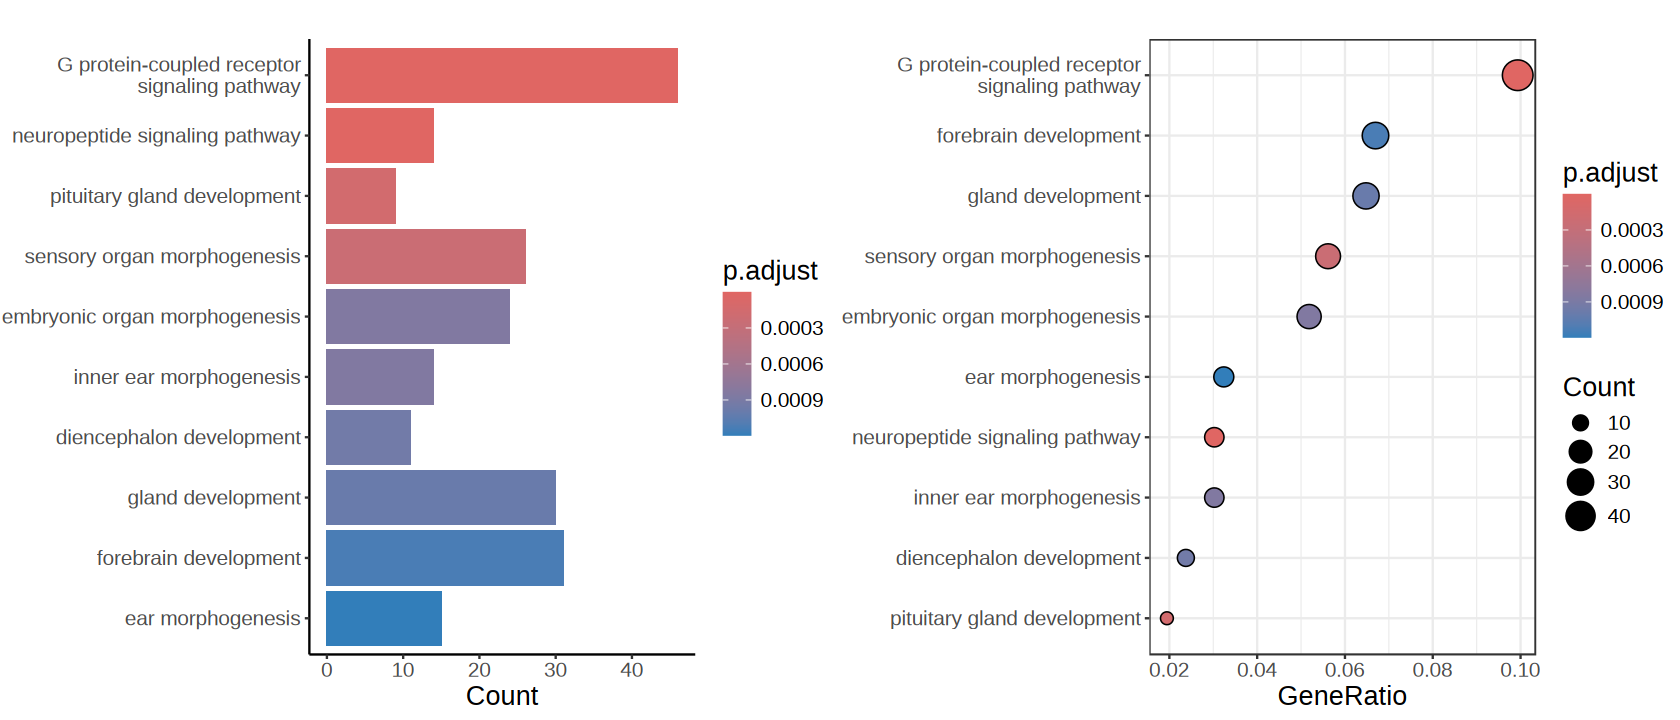

In [26]:
options(repr.plot.width = 14, repr.plot.height = 6)
p1 <- barplot(egoRes, showCategory = 10) + 
    theme_classic() + 
    theme(axis.title = element_text(size = 16), 
          axis.text = element_text(size = 12), 
          legend.title = element_text(size = 16), 
          legend.text = element_text(size = 12))
p2 <- dotplot(egoRes, showCategory = 10) + 
    theme_bw() +
    theme(axis.title = element_text(size = 16), 
          axis.text = element_text(size = 12), 
          legend.title = element_text(size = 16), 
          legend.text = element_text(size = 12))
cowplot::plot_grid(p1, p2, ncol = 2)

In [27]:
df <- as.data.frame(egoRes)
df$geneLabel <- apply(df, 1, function(x) {
    selected_genes <- strsplit(x[grep("geneID", colnames(df))], "/")[[1]]
    selected_genes <- intersect(degResult[order(degResult$logFC),]$gene_name, selected_genes)[1:5]
    paste(paste(selected_genes, collapse = ", "), " ...")
})
head(df, n = 1)

,ID,Description,GeneRatio,BgRatio,pvalue,p.adjust,qvalue,geneID,Count,geneLabel
,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<int>,<chr>
GO:0007186,GO:0007186,G protein-coupled receptor signaling pathway,46/463,494/14051,1.809229e-10,6.613251e-07,5.892154e-07,Ecel1/Pdyn/Tacr1/Drd2/Lpar6/Sstr4/Lpar1/C3ar1/Rgs8/Sstr3/Penk/Gpr6/Baiap3/Npy4r/Fzd9/Fzd2/Tac1/Gpr88/Met/Ly6g6e/Nts/Htr1a/Npr3/Grm2/Adgrf4/Adcyap1/Grp/Galr1/Dgka/Ntsr1/Vmn2r1/Tacr3/Npy/Itpr1/Gipr/Nr3c2/Ramp1/Npy1r/Ramp3/Gpr12/Npy5r/Adgrd1/Glp2r/Htr1f/Rgs9bp/Ptk2b,46,"Htr1f, Nts, Galr1, Gipr, Ptk2b ..."


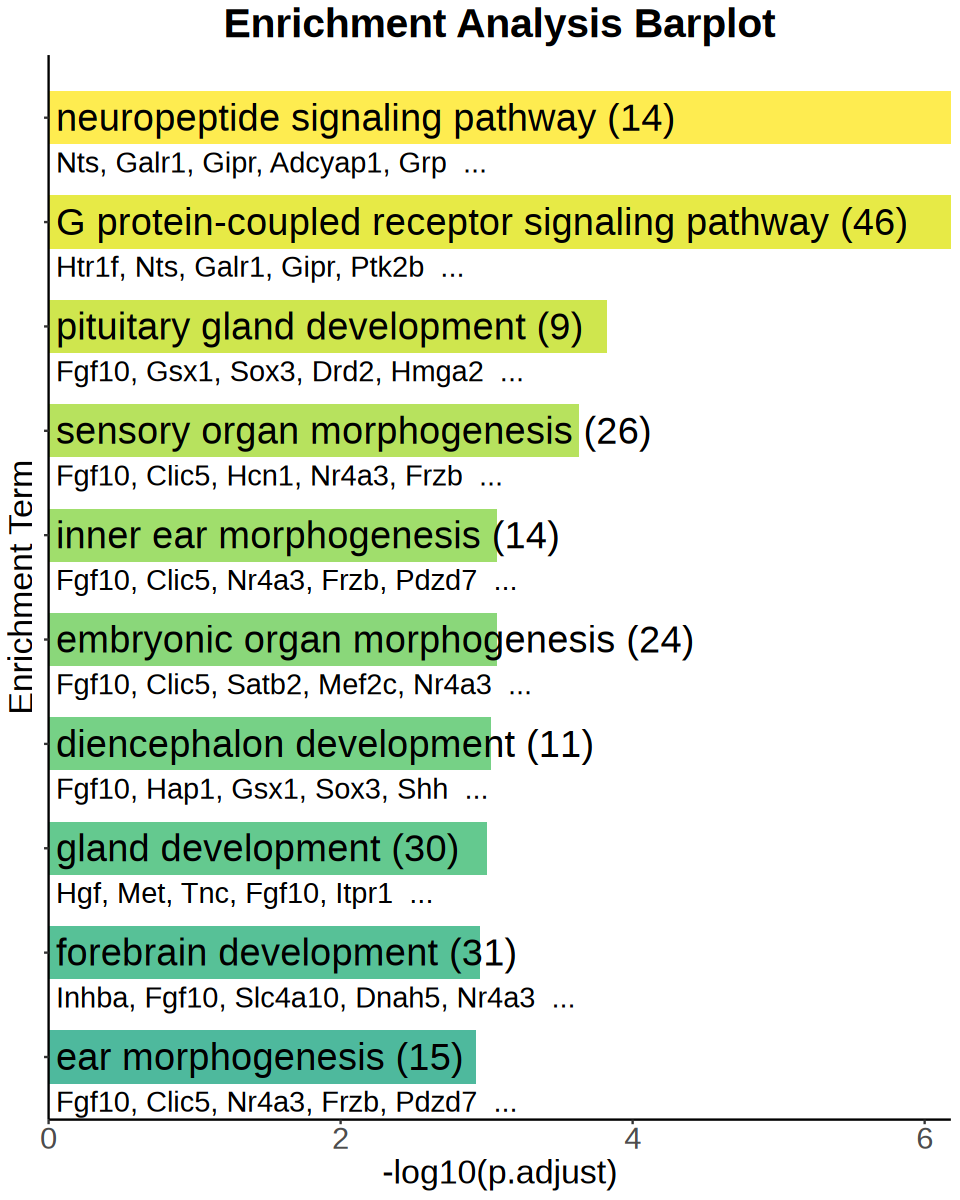

In [28]:
options(repr.plot.width = 8, repr.plot.height = 10)

ggplot(df[1:10,], aes(x = -log10(p.adjust), y = reorder(Description, -log10(p.adjust)), 
                      fill = reorder(Description, -log10(p.adjust)))) +
    geom_bar(stat = "identity", width = 0.5, alpha = 0.8) +
    geom_text(aes(x = 0.05, label = paste0(Description, " (", Count, ")")), size = 8, , hjust = 0) +
    geom_text(aes(x = 0.05, label = geneLabel), hjust = 0, vjust = 3, size = 6, color = "black", nudge_y = 0.05) +
    scale_x_continuous(expand = c(0,0)) +
    scale_fill_viridis_d(option = "D", begin = 0.6) +
    labs(title = "Enrichment Analysis Barplot", 
         x = "-log10(p.adjust)", y = "Enrichment Term") +
    theme_classic() + 
    theme(plot.title = element_text(size = 24, face = "bold", hjust = 0.5), 
          axis.title = element_text(size = 20),
          axis.text = element_text(size = 18),
          axis.text.y = element_blank(),
          legend.position = "none")

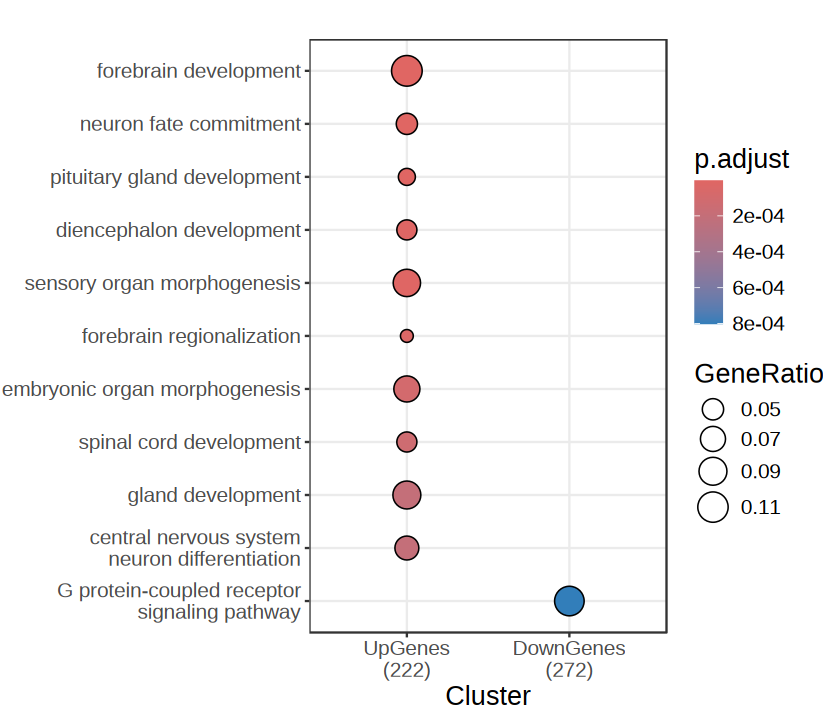

In [29]:
options(repr.plot.width = 7, repr.plot.height = 6)
dotplot(multi_egoRes, showCategory = 10) + 
    theme_bw() +
    theme(axis.title = element_text(size = 16), 
          axis.text = element_text(size = 12), 
          legend.title = element_text(size = 16), 
          legend.text = element_text(size = 12))

In [30]:
multi_egoRes.subset <- multi_egoRes |> as.data.frame() |> 
    mutate(Count = ifelse(Cluster == "DownGenes", -abs(Count), Count)) |> 
    group_by(Cluster) |> arrange(p.adjust) |> 
    slice_head(n = 10) |> ungroup() |>
    mutate(index = seq_len(n()))

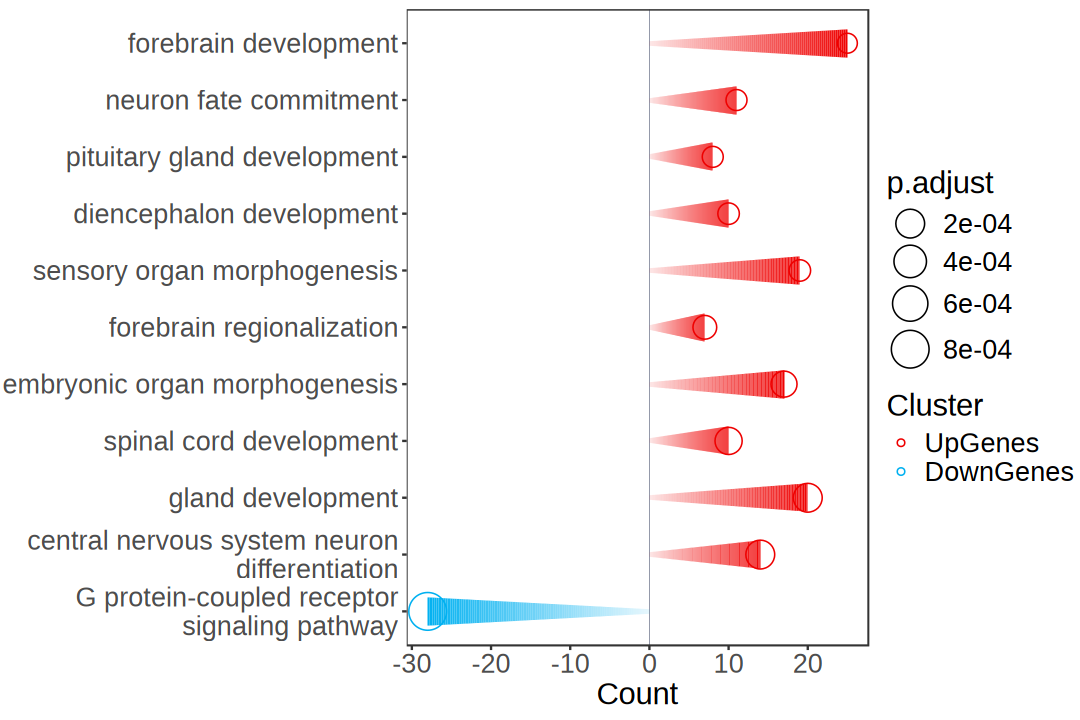

In [31]:
options(repr.plot.width = 9, repr.plot.height = 6)
ggplot(multi_egoRes.subset) +
    geom_point(aes(x = Count, y = reorder(Description, -index), color = Cluster, size = p.adjust), shape = 21, fill = "white") +
    # geom_text(aes(x = Count+5, y = reorder(Description, -index), label = paste0("p.adj: ", sprintf("%.2e", p.adjust))), 
    #           size = 6, color = "grey20", hjust = 0, nudge_x = 0.05) +
    geom_vline(xintercept = c(0), linewidth = 0.1, color = "#1f294e") +
    ggforce::geom_link(aes(x = 0, y = reorder(Description, -index), 
                           xend = Count, yend = reorder(Description, -index), 
                           linewidth = after_stat(index), alpha = after_stat(index), 
                           color = Cluster), show.legend = F) +
    scale_colour_manual(values = c("#EE0000", "#00B0F0")) +
    scale_size(range = c(5, 10)) +
    scale_y_discrete(labels = function(labels) str_wrap(labels, width = 30)) +
    labs(x = "Count", y = NULL) + 
    # guides(color = guide_legend('pathway condition'), size = guide_legend('metabolite counts in each pathway')) +
    theme_test() + 
    theme(axis.title = element_text(size = 18), 
          axis.text = element_text(size = 16), 
          legend.title = element_text(size = 18),
          legend.text = element_text(size = 16))

In [32]:
head(multi_egoRes.subset)

Cluster,ID,Description,GeneRatio,BgRatio,pvalue,p.adjust,qvalue,geneID,Count,index
<fct>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<int>,<int>
UpGenes,GO:0030900,forebrain development,25/222,372/14098,9.675224e-10,2.745829e-06,2.498245e-06,Nkx2-1/Shh/Hap1/Aldh1a3/Rarb/Ikzf1/Gli3/Id4/Otp/Dlx2/Uncx/Fezf1/Dlx5/Drd2/Zic1/Gsx2/Six3/Isl1/Sox3/Dmrta2/Gsx1/Hmga2/Pou3f4/Zic3/Lhx8,25,1
UpGenes,GO:0048663,neuron fate commitment,11/222,65/14098,4.891552e-09,5.410456e-06,4.922610e-06,Nkx2-1/Shh/Gli3/Dlx2/Zfp521/Gsx2/Isl1/Dmrt3/Dmrta2/Gsx1/Gbx1,11,2
UpGenes,GO:0021983,pituitary gland development,8/222,27/14098,5.719298e-09,5.410456e-06,4.922610e-06,Nkx2-1/Otp/Drd2/Six3/Isl1/Sox3/Gsx1/Hmga2,8,3
UpGenes,GO:0021536,diencephalon development,10/222,56/14098,1.447827e-08,8.802516e-06,8.008817e-06,Nkx2-1/Shh/Hap1/Otp/Drd2/Six3/Isl1/Sox3/Gsx1/Hmga2,10,4
UpGenes,GO:0090596,sensory organ morphogenesis,19/222,250/14098,1.550831e-08,8.802516e-06,8.008817e-06,Shh/Aldh1a3/Rarb/Ikzf1/Meis1/Ntn1/Gli3/Dlx6/Dlx5/Ush1c/Fgf3/Six4/Six3/Fzd2/Pou3f4/Hipk2/Zic3/Dio3/Cntf,19,5
UpGenes,GO:0021871,forebrain regionalization,7/222,25/14098,8.250311e-08,3.902397e-05,3.550528e-05,Nkx2-1/Shh/Gli3/Fezf1/Gsx2/Six3/Dmrta2,7,6


In [33]:
multi_egoRes.subset.mat <- multi_egoRes.subset[,c("Description", "Cluster", "p.adjust")] |>
    pivot_wider(names_from = Cluster, values_from = p.adjust) |> 
    column_to_rownames(var = "Description") |>
    as.matrix()
multi_egoRes.subset.mat |> head()

,UpGenes,DownGenes
forebrain development,2.745829e-06,NA
neuron fate commitment,5.410456e-06,NA
pituitary gland development,5.410456e-06,NA
diencephalon development,8.802516e-06,NA
sensory organ morphogenesis,8.802516e-06,NA
forebrain regionalization,3.902397e-05,NA


In [34]:
multi_egoRes.subset.mat

,UpGenes,DownGenes
forebrain development,2.745829e-06,NA
neuron fate commitment,5.410456e-06,NA
pituitary gland development,5.410456e-06,NA
diencephalon development,8.802516e-06,NA
sensory organ morphogenesis,8.802516e-06,NA
forebrain regionalization,3.902397e-05,NA
embryonic organ morphogenesis,9.606329e-05,NA
spinal cord development,1.341893e-04,NA
gland development,2.023969e-04,NA
central nervous system neuron differentiation,2.023969e-04,NA


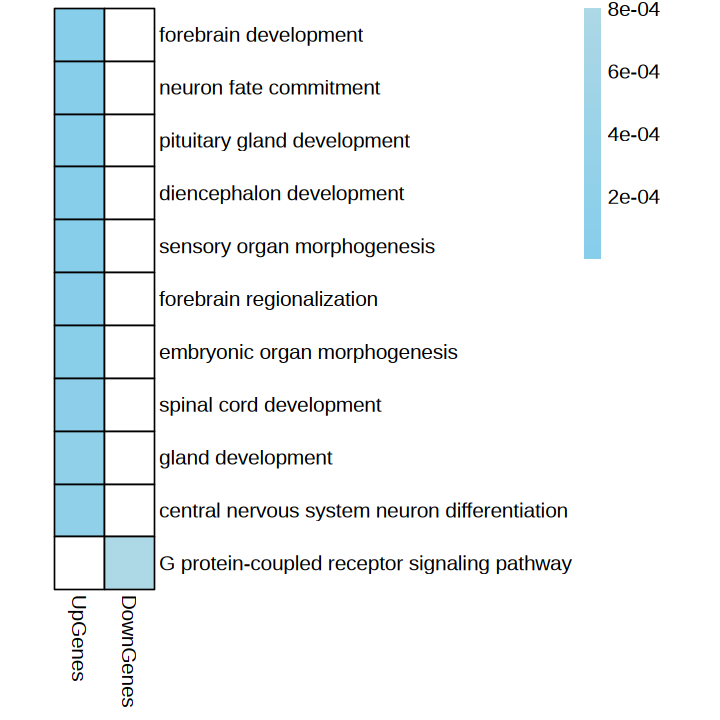

In [35]:
options(repr.plot.width = 6, repr.plot.height = 6)
pheatmap(multi_egoRes.subset.mat, border_color = NULL, cellwidth = 30, fontsize = 12,
         color = colorRampPalette(c("skyblue", "lightblue"))(50), na_col = "white",
         show_rownames = T, show_colnames = T, 
         cluster_rows = F, cluster_cols = F)

In [162]:
mego_res |> dplyr::select(-one_of("geneID")) |> head()

,Cluster,ONTOLOGY,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,DESeq2-Up,BP,GO:0050673,epithelial cell proliferation,38/491,370/13607,0.10270270,2.846183,6.966041,5.983244e-09,1.567515e-05,1.365305e-05,38
2,DESeq2-Up,BP,GO:0010817,regulation of hormone levels,40/491,406/13607,0.09852217,2.730328,6.848467,7.738902e-09,1.567515e-05,1.365305e-05,40
3,DESeq2-Up,BP,GO:0007411,axon guidance,25/491,187/13607,0.13368984,3.704924,7.206176,1.535241e-08,1.734052e-05,1.510359e-05,25
4,DESeq2-Up,BP,GO:0097485,neuron projection guidance,25/491,188/13607,0.13297872,3.685217,7.173044,1.712221e-08,1.734052e-05,1.510359e-05,25
5,DESeq2-Up,BP,GO:0040017,positive regulation of locomotion,44/491,490/13607,0.08979592,2.488499,6.492839,2.243907e-08,1.818014e-05,1.583490e-05,44
6,DESeq2-Up,BP,GO:2000147,positive regulation of cell motility,43/491,479/13607,0.08977035,2.487791,6.413802,3.298155e-08,2.067196e-05,1.800528e-05,43


In [267]:
plot_df <- mego_res |> as.data.frame() |>
    dplyr::select(Cluster, ONTOLOGY, Description, p.adjust) |>
    filter(ONTOLOGY == "BP") |>
    group_by(Cluster) |>
    arrange(p.adjust, .by_group = TRUE) |>
    slice_head(n = 10) |>
    mutate(Description = factor(
        Description, levels = unique(Description))) |>
    ungroup() |>
    complete(Cluster, ONTOLOGY, Description, fill = list(qvalue = NA))

    # pivot_wider(names_from = Cluster, values_from = p.adjust) |> 

 # Sample = gsub("_", "\n", Sample), 

In [268]:
head(plot_df)

Cluster,ONTOLOGY,Description,p.adjust
<fct>,<chr>,<fct>,<dbl>
DESeq2-Up,BP,epithelial cell proliferation,1.567515e-05
DESeq2-Up,BP,regulation of hormone levels,1.567515e-05
DESeq2-Up,BP,axon guidance,1.734052e-05
DESeq2-Up,BP,neuron projection guidance,1.734052e-05
DESeq2-Up,BP,positive regulation of locomotion,1.818014e-05
DESeq2-Up,BP,positive regulation of cell motility,2.067196e-05


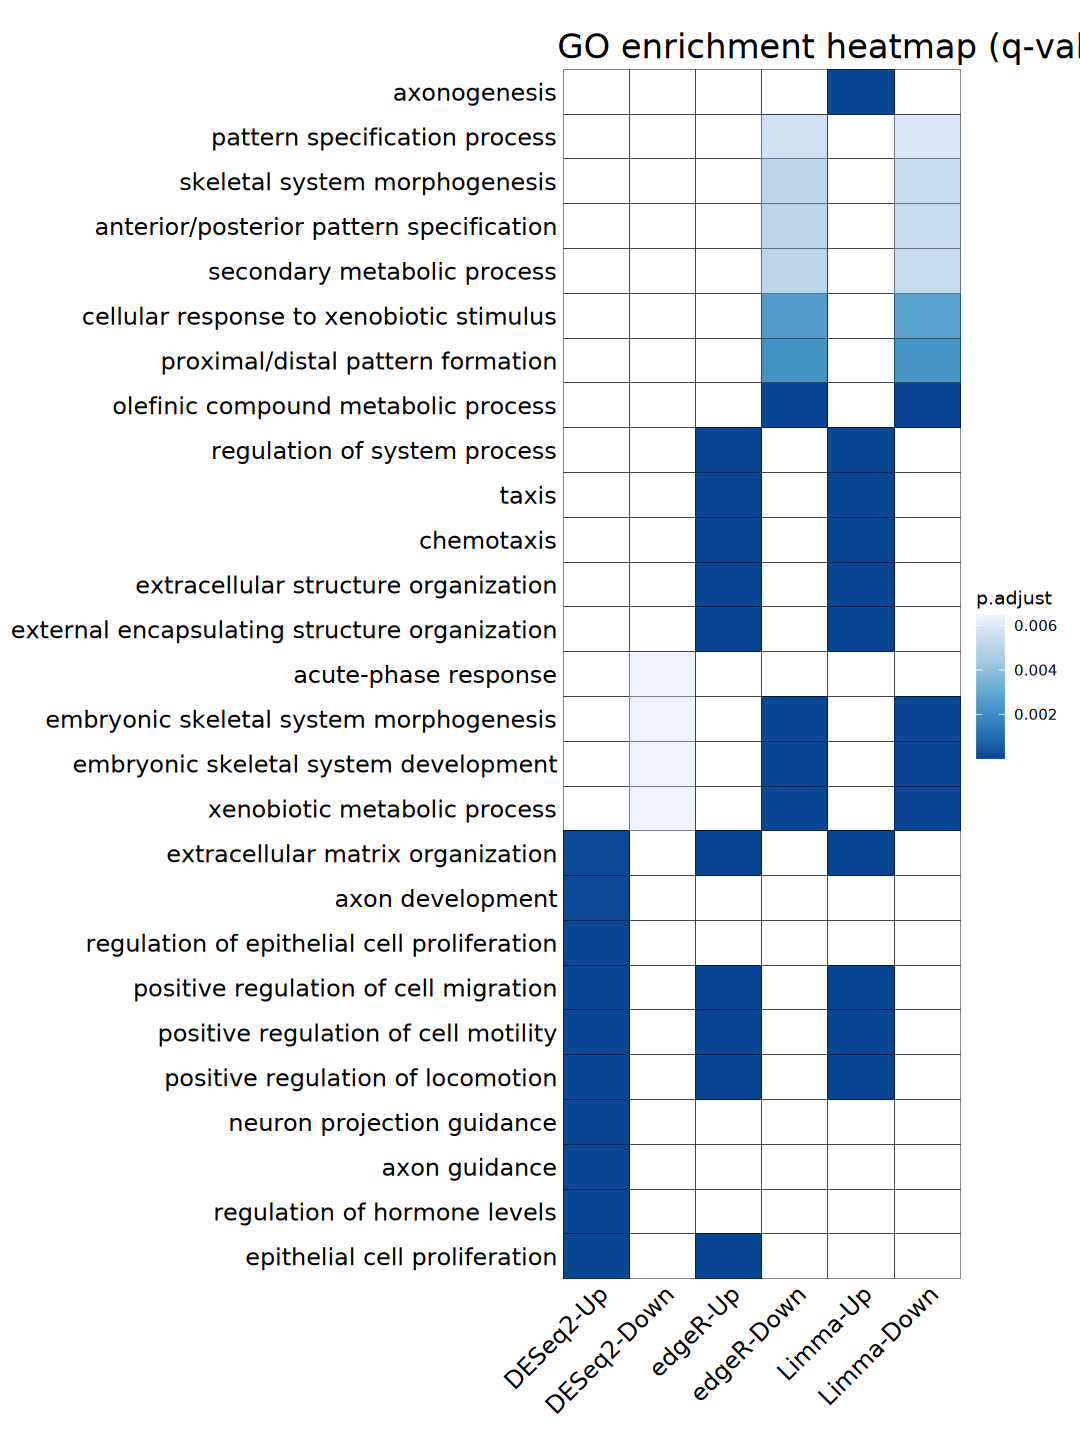

In [269]:
options(repr.plot.width = 9, repr.plot.height = 12)
ggplot(plot_df, aes(x = Cluster, y = Description)) +
    geom_tile(aes(fill = p.adjust), color = "black") +
    # scale_y_discrete(labels = scales::wrap_format(40)) +
    scale_fill_distiller(
        palette = "Blues", direction = -1, na.value = NA) + 
    labs(title = "GO enrichment heatmap (q-value)",
         x = NULL, y = NULL) + 
    theme_void() +
    theme(plot.title = element_text(size = 20),
          axis.text.x = element_text(size = 14, angle = 45, hjust = 1, vjust = 1),
          axis.text.y = element_text(size = 14, hjust = 1), 
          plot.margin = unit(c(1, 1, 1, 1), "line"))

#### Tree plot

In [36]:
egoRes_similarityMatrix <- pairwise_termsim(egoRes)

! # Invaild edge matrix for <phylo>. A <tbl_df> is returned.

! # Invaild edge matrix for <phylo>. A <tbl_df> is returned.

! # Invaild edge matrix for <phylo>. A <tbl_df> is returned.

! # Invaild edge matrix for <phylo>. A <tbl_df> is returned.

! # Invaild edge matrix for <phylo>. A <tbl_df> is returned.

! # Invaild edge matrix for <phylo>. A <tbl_df> is returned.

! # Invaild edge matrix for <phylo>. A <tbl_df> is returned.

! # Invaild edge matrix for <phylo>. A <tbl_df> is returned.

! # Invaild edge matrix for <phylo>. A <tbl_df> is returned.

! # Invaild edge matrix for <phylo>. A <tbl_df> is returned.

! # Invaild edge matrix for <phylo>. A <tbl_df> is returned.

! # Invaild edge matrix for <phylo>. A <tbl_df> is returned.

! # Invaild edge matrix for <phylo>. A <tbl_df> is returned.

! # Invaild edge matrix for <phylo>. A <tbl_df> is returned.

! # Invaild edge matrix for <phylo>. A <tbl_df> is returned.

! # Invaild edge matrix for <phylo>. A <tbl_df> is returned.

! # Inva

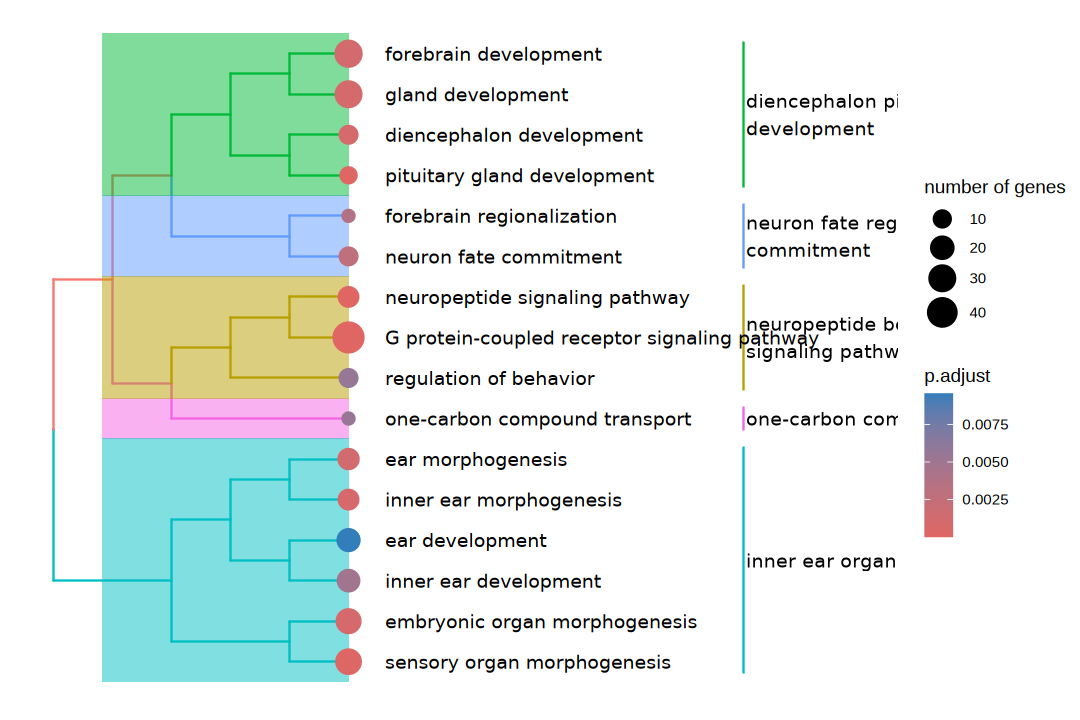

In [37]:
options(repr.plot.width = 9, repr.plot.height = 6)
treeplot(egoRes_similarityMatrix)

#### Gene-Concept Network & Heatmap

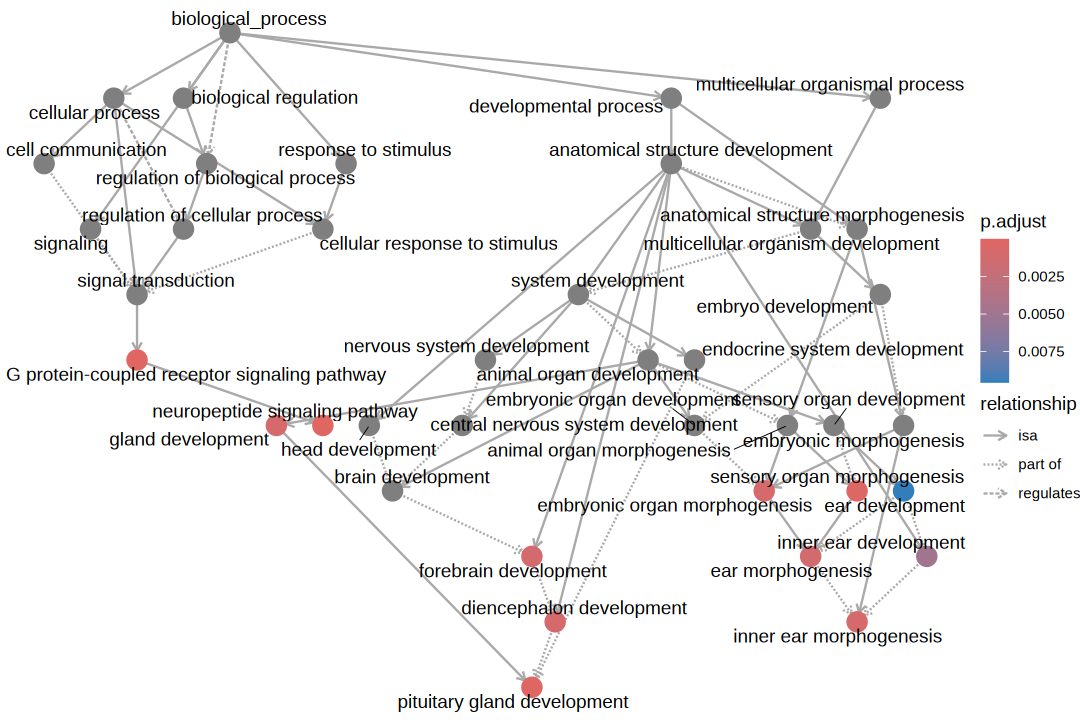

In [38]:
options(repr.plot.width = 9, repr.plot.height = 6)
goplot(egoRes)

Warning message:
“ggrepel: 27 unlabeled data points (too many overlaps). Consider increasing max.overlaps”
Warning message:
“ggrepel: 27 unlabeled data points (too many overlaps). Consider increasing max.overlaps”
Warning message:
“ggrepel: 32 unlabeled data points (too many overlaps). Consider increasing max.overlaps”


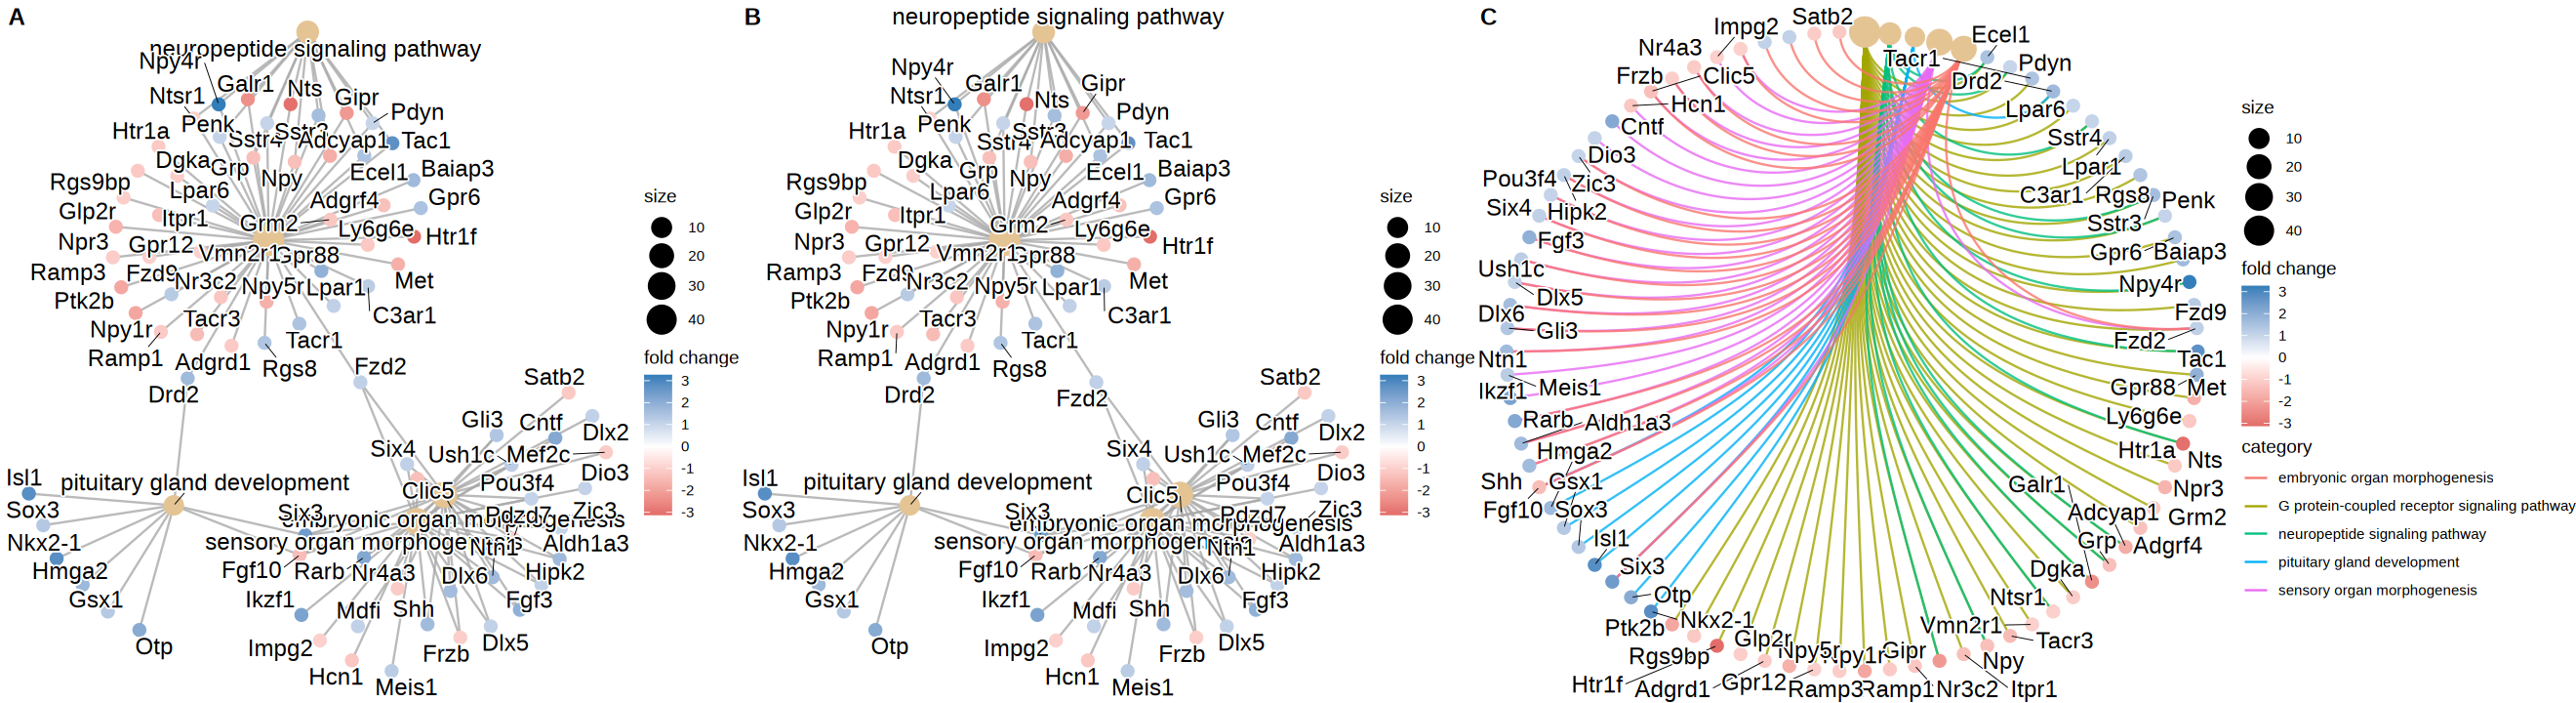

In [39]:
options(repr.plot.width = 22, repr.plot.height = 6)
p1 <- cnetplot(egoRes, color.params = list(foldChange = genelogFC), max.overlaps = 10000)
p2 <- cnetplot(egoRes, color.params = list(foldChange = genelogFC), max.overlaps = 10000, categorySize = "pvalue")
p3 <- cnetplot(egoRes, color.params = list(foldChange = genelogFC, edge = TRUE), max.overlaps = 10000, circular = TRUE) 
plot_grid(p1, p2, p3, ncol = 3, labels = LETTERS[1:3], rel_widths = c(.8, .8, 1.2))

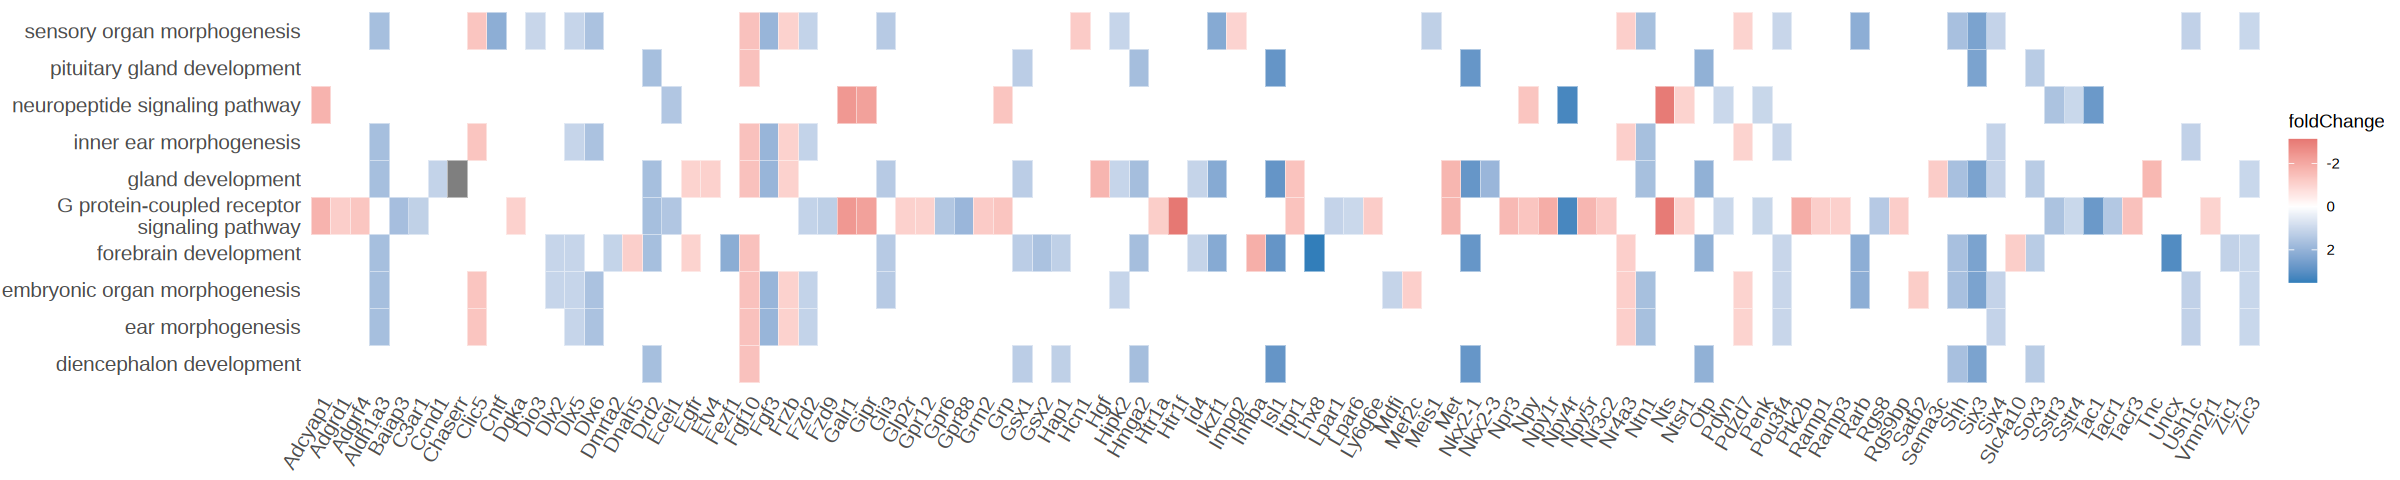

In [40]:
options(repr.plot.width = 20, repr.plot.height = 4)
heatplot(egoRes, showCategory = 10, foldChange = genelogFC) + 
    theme(axis.text = element_text(size = 12))

#### Enrichment Map

In [41]:
egoRes_similarityMatrix <- pairwise_termsim(egoRes)

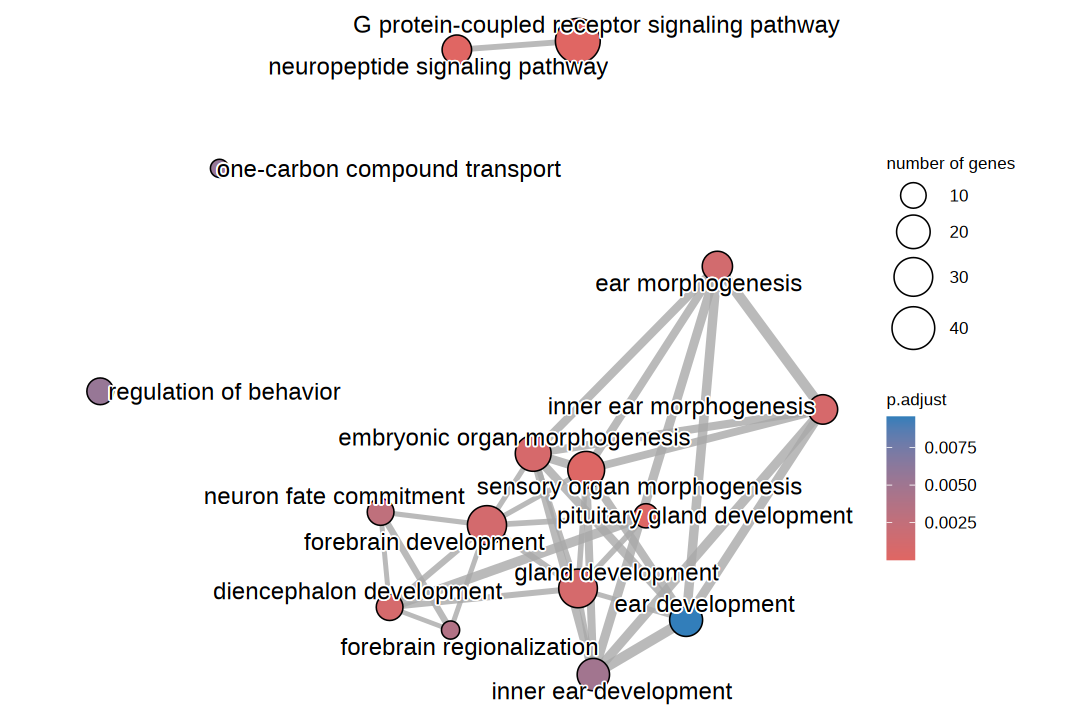

In [42]:
options(repr.plot.width = 9, repr.plot.height = 6)
emapplot(egoRes_similarityMatrix, cex.params = list(category_node = 1.5), layout.params = list(layout = "kk"))

In [43]:
multi_egoRes_similarityMatrix <- pairwise_termsim(multi_egoRes)

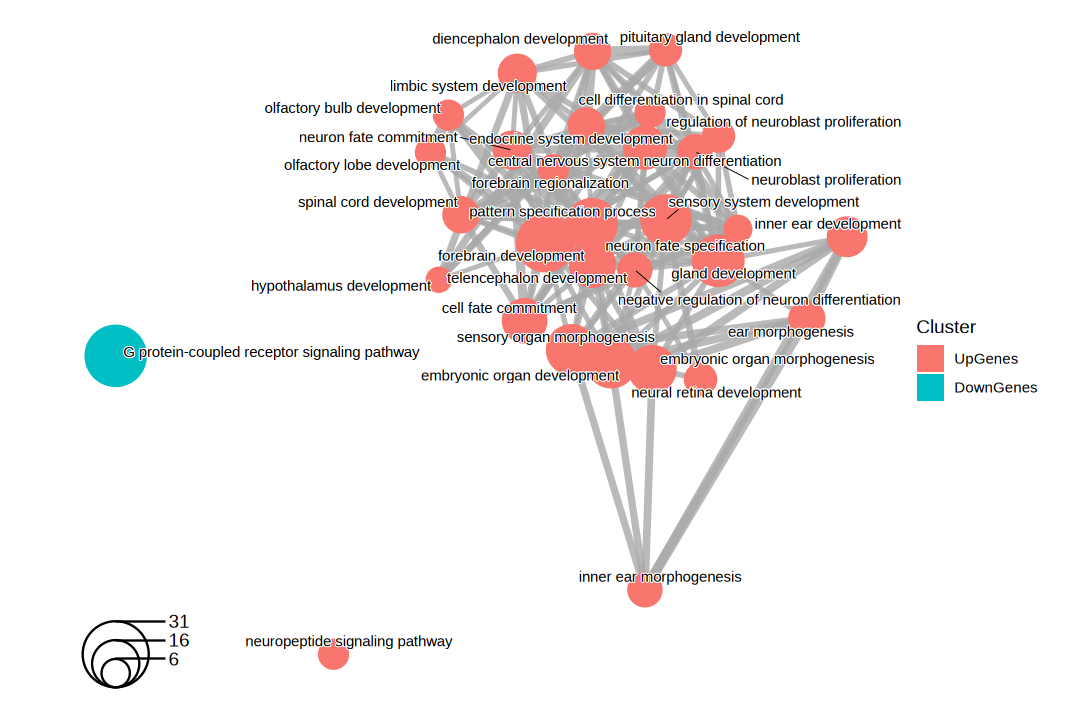

In [44]:
options(repr.plot.width = 9, repr.plot.height = 6)
emapplot(multi_egoRes_similarityMatrix, 
         pie.params = list(legend_n = 3),
         cex.params = list(category_node = 1.5), 
         layout.params = list(layout = "kk"))


groupGOTerms: 	GOBPTerm, GOMFTerm, GOCCTerm environments built.


Building most specific GOs .....

	( 5307 GO terms found. )


Build GO DAG topology ..........

	( 5307 GO terms and 11547 relations. )


Annotating nodes ...............

	( 14051 genes annotated to the GO terms. )

Loading required package: Rgraphviz

Loading required package: graph


Attaching package: ‘graph’


The following object is masked from ‘package:stringr’:

    boundary


Loading required package: grid


Attaching package: ‘Rgraphviz’


The following objects are masked from ‘package:IRanges’:

    from, to


The following objects are masked from ‘package:S4Vectors’:

    from, to




$dag
A graphNEL graph with directed edges
Number of Nodes = 39 
Number of Edges = 66 

$complete.dag
[1] "A graph with 39 nodes."


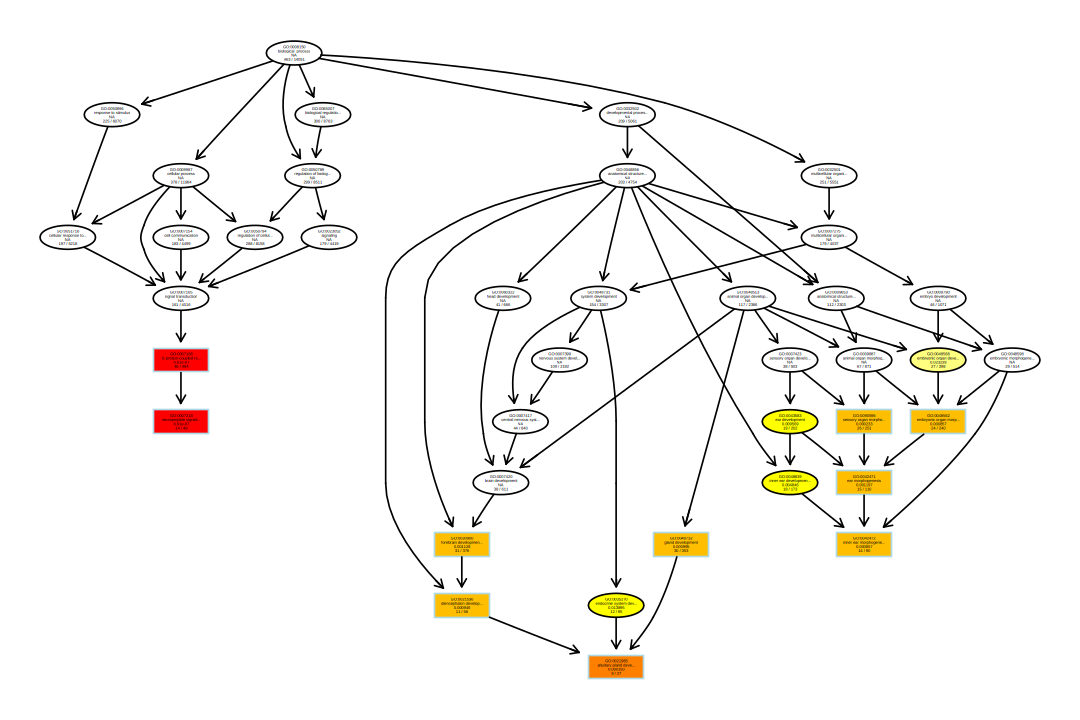

In [45]:
options(repr.plot.width = 9, repr.plot.height = 6)
plotGOgraph(egoRes)

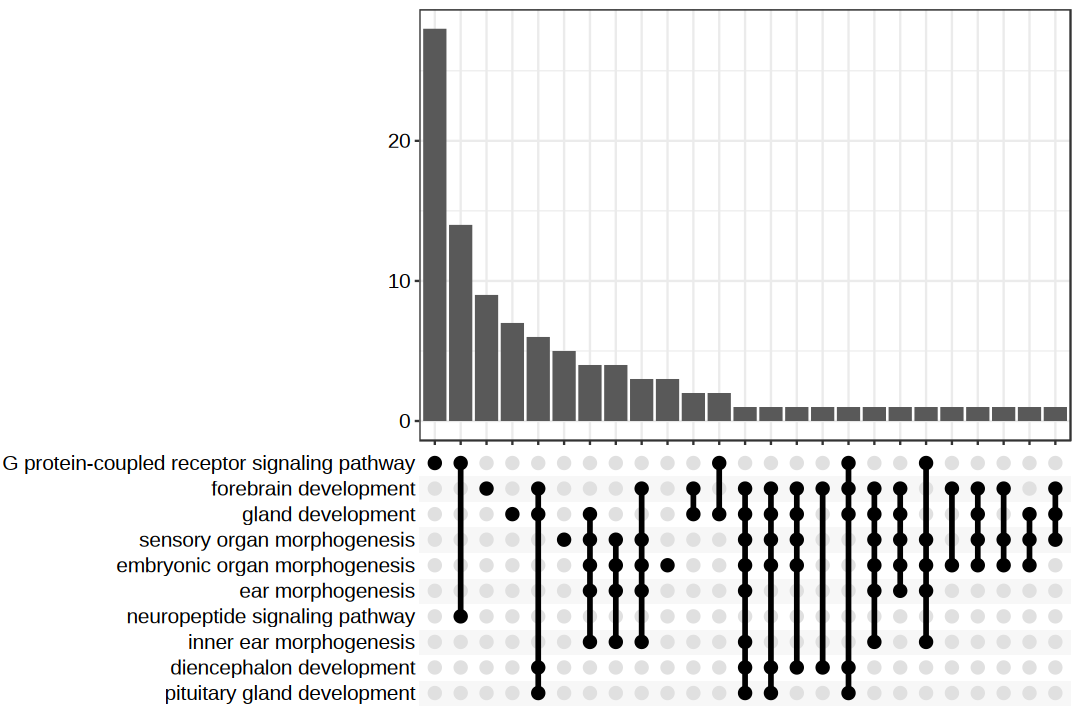

In [46]:
options(repr.plot.width = 9, repr.plot.height = 6)
upsetplot(egoRes)

#### KEGG pathway

In [47]:
genelogFCkegg <- degResult$logFC
names(genelogFCkegg) <- degResult$ENTREZID
head(genelogFCkegg)

14679       12544       14955      107815       67608       12390 
-0.07571572  0.31959865  0.32290608 -0.68559174 -0.24089747 -0.76960124

In [48]:
# browseKEGG(ekeggRes, pathID = 'mmu04080')

In [49]:
mmu04080 <- pathview(gene.data = genelogFCkegg, species = "mmu", pathway.id = "mmu04080",
                     limit = list(gene = max(abs(genelogFCkegg)), cpd = 1))

'select()' returned 1:1 mapping between keys and columns

Info: Working in directory /Data2/caoq/testPath/riboSeqTest/riboseqPE150L/test

Info: Writing image file mmu04080.pathview.png



In [ ]:
# getAnywhere(get_KEGG_db)
# eval(parse(text = paste0(annoDb, "::", kw)))
# function (gene, organism = "hsa", keyType = "kegg", pvalueCutoff = 0.05, 
#     pAdjustMethod = "BH", universe, minGSSize = 10, maxGSSize = 500, 
#     qvalueCutoff = 0.2, use_internal_data = FALSE) 
# {
#     if (inherits(organism, "character")) {
#         if (organism == "cpd") {
#             organism = gson_cpd()
#         }
#     }
#     if (inherits(organism, "character")) {
#         species <- organismMapper(organism)
#         if (use_internal_data) {
#             KEGG_DATA <- get_data_from_KEGG_db(species)
#         }
#         else {
#             KEGG_DATA <- prepare_KEGG(species, "KEGG", keyType)
#         }
#     }
#     else if (inherits(organism, "GSON")) {
#         KEGG_DATA <- organism
#         species <- KEGG_DATA@species
#         keyType <- KEGG_DATA@keytype
#     }
#     else {
#         stop("organism should be a species name or a GSON object")
#     }
#     res <- enricher_internal(gene, pvalueCutoff = pvalueCutoff, 
#         pAdjustMethod = pAdjustMethod, universe = universe, minGSSize = minGSSize, 
#         maxGSSize = maxGSSize, qvalueCutoff = qvalueCutoff, USER_DATA = KEGG_DATA)
#     if (is.null(res)) 
#         return(res)
#     res@ontology <- "KEGG"
#     res@organism <- species
#     res@keytype <- keyType
#     res <- append_kegg_category(res)
#     return(res)
# }

## GSEA

Gene Set Enrichment Analysis

1. Calculation of an Enrichment Score
2. Esimation of Significance Level of ES
3. Adjustment for Multiple Hypothesis Testing

### clusterProfiler

In [50]:
genelogFC <- degResult$logFC
names(genelogFC) <- degResult$gene_name
genelogFC <- sort(genelogFC, decreasing = T)
head(genelogFC)

Tgm7 AI606473    Ntrk1  Gm11620     Lhx8  Fndc3c1 
4.495641 4.145681 3.955643 3.847580 3.517215 3.511460

In [51]:
ggoRes <- gseGO(geneList = genelogFC, ont = "BP", 
                keyType = "SYMBOL", OrgDb = org.Mm.eg.db, 
                pAdjustMethod = "BH", pvalueCutoff  = 0.05, eps = 0, 
                by = "fgsea", verbose = FALSE)
head(ggoRes, n = 2)

Warning message in preparePathwaysAndStats(pathways, stats, minSize, maxSize, gseaParam, :
“There are duplicate gene names, fgsea may produce unexpected results.”


,ID,Description,setSize,enrichmentScore,NES,pvalue,p.adjust,qvalue,rank,leading_edge,core_enrichment
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
GO:0030900,GO:0030900,forebrain development,372,0.4566654,2.116734,2.873635e-14,1.664697e-10,1.437423e-10,2209,"tags=26%, list=13%, signal=23%",Lhx8/Uncx/Isl1/Nkx2-1/Six3/Ikzf1/Fezf1/Rarb/Otp/Hmga2/Drd2/Aldh1a3/Shh/Gsx2/Gli3/Sox3/Gsx1/Hap1/Zic1/Neurog1/Dmrta2/Id4/Dlx2/Dlx5/Pou3f4/Zic3/Fut10/Btbd3/Efhc1/Htr6/Sox1/Akna/Sall1/Otx2/Notch3/Nr2e1/Sox2/Lhx1/Bcl11b/Gli2/Notch1/Bmp2/Nr2f2/Arx/Slit1/Crkl/Lmx1a/Wnt3a/Dlx1/Tsku/Wdr89/Kif14/Zic5/E2f1/Arhgap35/Hes1/Arid1a/Ephb2/Foxp2/Smo/Btg2/Pex13/Aspm/Kcna1/Alk/Mettl3/Nde1/Fezf2/Lef1/Aqp1/Col3a1/Wnt2b/Chd7/Emx1/Tacc3/Ascl1/Lrp2/Tbr1/Ndst1/Nr2f1/Rtn4rl2/Coro1c/Cntnap2/Hes5/Stil/Tyro3/Ogdh/Kif26a/Trp73/Rfx4/Bmp4/Otx1/Fgf2/Rbpj/Slc1a2
GO:0007389,GO:0007389,pattern specification process,361,0.4423013,2.049803,2.521246e-12,6.864591e-09,5.927396e-09,2856,"tags=32%, list=17%, signal=27%",Uncx/Isl1/Nkx2-1/Six3/Fezf1/Fgf3/Shh/Gsx2/Gli3/Meis1/Zic1/Neurog1/Dmrta2/Pld6/Mdfi/Dnaaf2/Dlx2/Hipk2/Tcf7l1/Hey1/Zic3/Dmrt3/Acvr2b/Sox1/Otx2/Tgif1/Efnb1/Lhx1/Arc/Gli2/Shroom3/Zic2/Notch1/Cfap53/Bmp2/Tshz1/Nr2f2/Helt/Irx3/Pcsk6/Vangl2/Ror2/Cited2/Crkl/Peg12/Wnt3a/Sp8/Dlx1/Bmp5/Nrarp/Aurka/Cited1/Gpc3/Bhlhe41/Hes1/Smo/Btg2/Lrp4/Lama5/Bicc1/Epb41l5/Crb2/Ptch1/Edn1/Smad6/Dand5/Fezf2/Snai1/Lef1/Wnt2b/Meis2/Emx1/Wnt6/Folr1/Wif1/Tifab/Ascl1/Lrp2/Palb2/Chsy1/Dll1/Tbr1/Nr2f1/Cyp26b1/Hes5/Mfng/Stil/Smad3/Cfap52/Wls/Bmp7/Lefty2/Rfx4/Bmp4/Hey2/Otx1/Fgf2/Rbpj/Axin2/Wnt7a/Gdf11/Dnah11/Ooep/C2cd3/Foxj1/Erbb4/Lrp5/Tll1/Axin1/C1qa/Nog/Ep300/Msx1/Ssbp3/Smad4/Gja1/Lfng


In [52]:
genelogFCkegg <- degResult$logFC
names(genelogFCkegg) <- degResult$ENTREZID
genelogFCkegg <- sort(genelogFCkegg, decreasing = T)
head(genelogFCkegg)

640543     <NA>    18211     <NA>    16875   333564 
4.495641 4.145681 3.955643 3.847580 3.517215 3.511460

In [53]:
gkeggRes <- gseKEGG(geneList = genelogFCkegg, organism = "mmu",
                    pAdjustMethod = "BH", pvalueCutoff = 0.05, verbose = FALSE)
head(gkeggRes, n = 1)

Reading KEGG annotation online: "https://rest.kegg.jp/link/mmu/pathway"...

Reading KEGG annotation online: "https://rest.kegg.jp/list/pathway/mmu"...

Warning message in preparePathwaysAndStats(pathways, stats, minSize, maxSize, gseaParam, :
“There are duplicate gene names, fgsea may produce unexpected results.”


,ID,Description,setSize,enrichmentScore,NES,pvalue,p.adjust,qvalue,rank,leading_edge,core_enrichment
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
mmu05217,mmu05217,Basal cell carcinoma - Mus musculus (house mouse),56,0.6889945,2.414225,9.351513e-10,3.123405e-07,2.697173e-07,2747,"tags=54%, list=17%, signal=45%",20423/14634/14371/57265/21415/22423/12575/22409/14633/12156/23882/22416/14370/319757/19206/16842/22414/22420/27015/17873/12159/16576/14366/12006/22421/12018/14368/14369/12005/21416


In [54]:
gmkeggRes <- gseMKEGG(geneList = genelogFCkegg, organism = 'mmu', pvalueCutoff = 1)
head(gmkeggRes, n = 1)

Reading KEGG annotation online: "https://rest.kegg.jp/link/mmu/module"...

Reading KEGG annotation online: "https://rest.kegg.jp/list/module"...

preparing geneSet collections...

GSEA analysis...

Warning message in preparePathwaysAndStats(pathways, stats, minSize, maxSize, gseaParam, :
“There are duplicate gene names, fgsea may produce unexpected results.”
leading edge analysis...

done...

--> Not a KEGG enrichment result



,ID,Description,setSize,enrichmentScore,NES,pvalue,p.adjust,qvalue,rank,leading_edge,core_enrichment
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
M00095,M00095,"C5 isoprenoid biosynthesis, mevalonate pathway",10,-0.6514155,-1.506906,0.06628788,0.6408656,0.6408656,3173,"tags=60%, list=19%, signal=48%",15357/110460/192156/319554/208715/224530


In [55]:
term2Gene <- msigdbr(species = "Mus musculus") |> 
    dplyr::select(gs_name, gene_symbol)
head(term2Gene)

gs_name,gene_symbol
<chr>,<chr>
AAACCAC_MIR140,Abcc4
AAACCAC_MIR140,Abraxas2
AAACCAC_MIR140,Actn4
AAACCAC_MIR140,Acvr1
AAACCAC_MIR140,Adam9
AAACCAC_MIR140,Adamts5


In [56]:
gseaRes <- GSEA(genelogFC, TERM2GENE = term2Gene)
head(gseaRes, n = 1)

preparing geneSet collections...

GSEA analysis...

Warning message in preparePathwaysAndStats(pathways, stats, minSize, maxSize, gseaParam, :
“There are duplicate gene names, fgsea may produce unexpected results.”
Warning message in fgseaMultilevel(pathways = pathways, stats = stats, minSize = minSize, :
“For some pathways, in reality P-values are less than 1e-10. You can set the `eps` argument to zero for better estimation.”
leading edge analysis...

done...



,ID,Description,setSize,enrichmentScore,NES,pvalue,p.adjust,qvalue,rank,leading_edge,core_enrichment
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
ZHONG_PFC_MAJOR_TYPES_NPCS,ZHONG_PFC_MAJOR_TYPES_NPCS,ZHONG_PFC_MAJOR_TYPES_NPCS,135,0.6763983,2.765269,1e-10,5.069592e-08,4.505908e-08,3859,"tags=68%, list=23%, signal=53%",Cdca5/Gli3/Sox3/Fen1/Cdca4/Id4/Zfhx4/Cdca7/Tgif1/Efnb1/Sox9/Notch1/Mki67/Aurkb/Ckap2l/Fbxo5/Ckap2/Dach1/Sgo2a/Birc5/Cenpf/Mcm5/Sgo1/Dlgap5/Mcm2/Mcm3/Gtse1/Uhrf1/Hes1/Gmnn/Aspm/Gins2/Depdc1b/Pimreg/Spag5/Creb5/Rrm2/Clspn/Ccnb1/Cdc20/Tpx2/Emx1/Kif2c/Nuf2/Ube2c/Tacc3/Bub1/Top2a/Mis18bp1/Cenpn/Melk/Cdk1/Dhfr/Rcn1/Pclaf/Clic1/Cks1b/Rrm1/Otx1/Mad2l1/Cdca3/Smc2/Prr11/Tmem98/Kif23/Pbk/Snrpb/Cks2/Sinhcaf/Hat1/Tmpo/Mcm7/Cenpu/Mcm4/Hells/Mdk/Mcm6/Tuba1b/Nusap1/Kpna2/Ccna2/Knstrn/Hmgb2/Tubb4b/Plpp3/Atad2/Gng5/Cenpk/Mfap2/Kif22/Eomes/Kif15


### Visualization

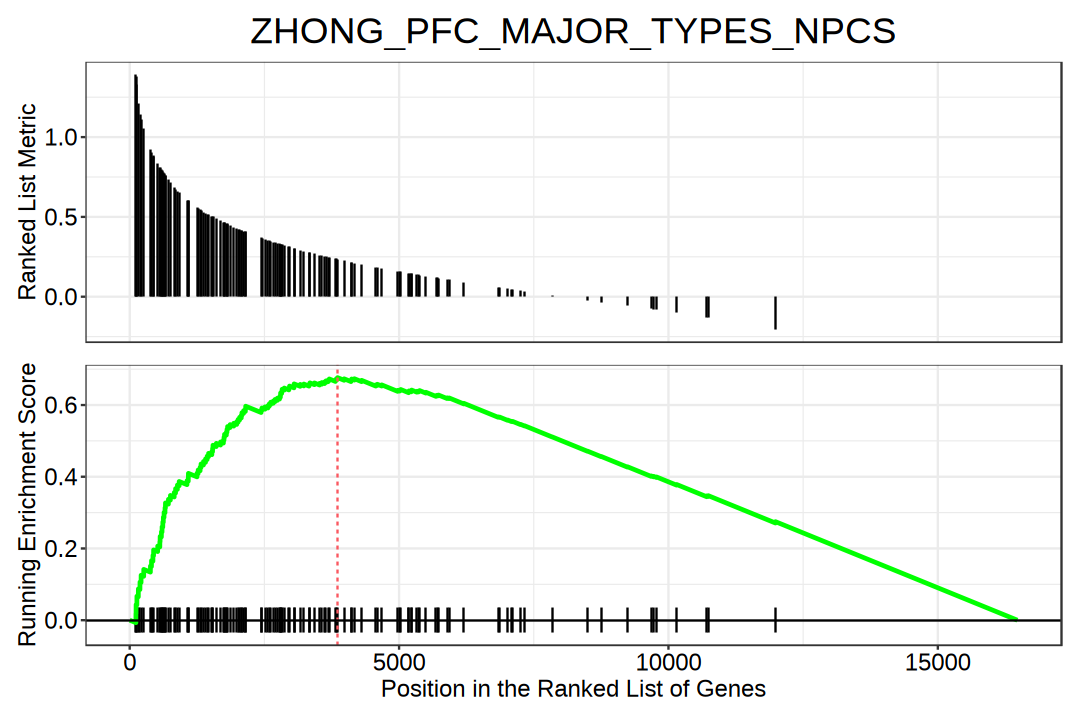

In [57]:
options(repr.plot.width = 9, repr.plot.height = 6)
gseaplot(gseaRes, geneSetID = 1, title = gseaRes$Description[1])

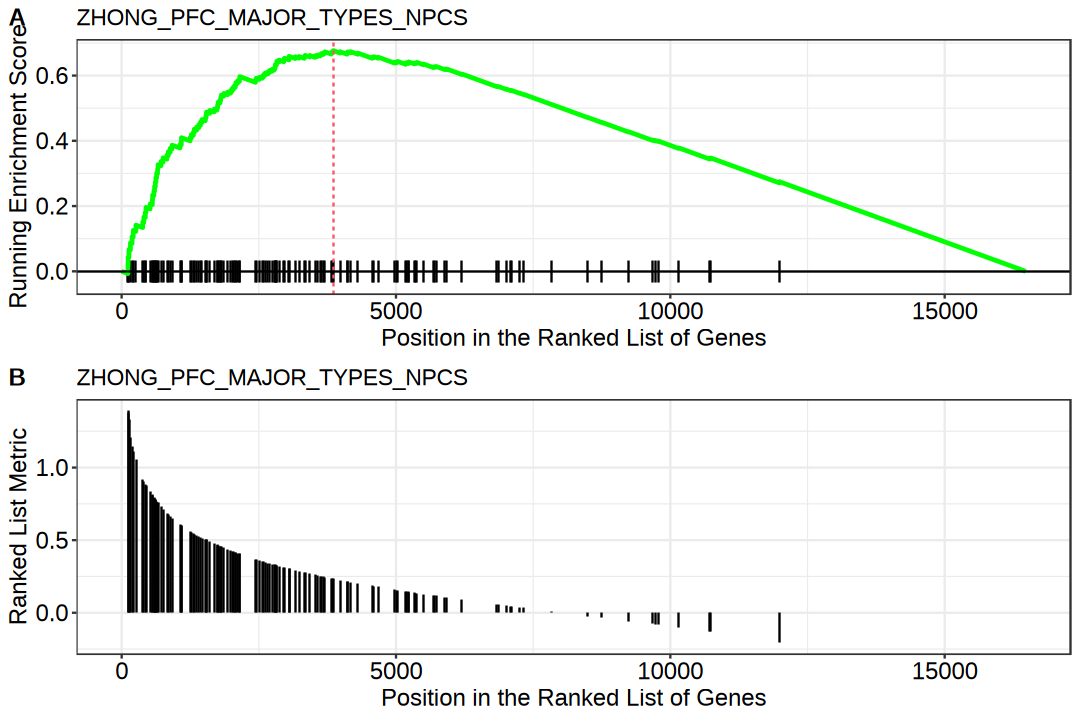

In [58]:
options(repr.plot.width = 9, repr.plot.height = 6)
p1 <- gseaplot(gseaRes, geneSetID = 1, by = "runningScore", title = gseaRes$Description[1])
p2 <- gseaplot(gseaRes, geneSetID = 1, by = "preranked", title = gseaRes$Description[1])
plot_grid(p1, p2, ncol=1, labels=LETTERS[1:3])
# (p1 / p2) + plot_annotation(tag_levels = 'A')

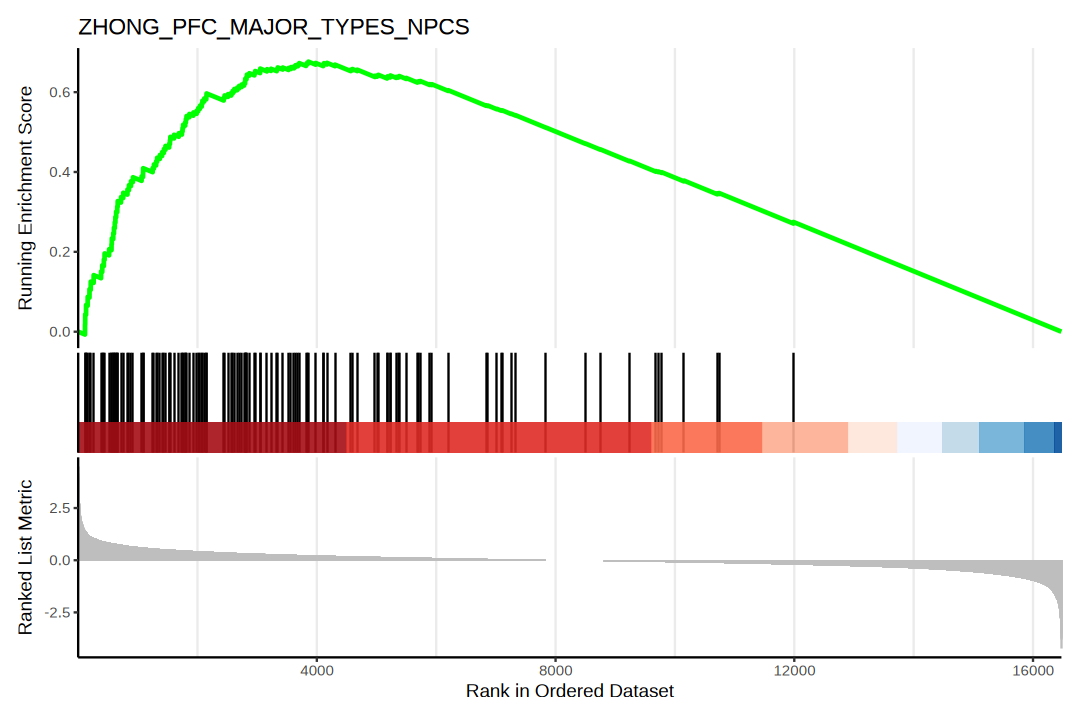

In [59]:
options(repr.plot.width = 9, repr.plot.height = 6)
gseaplot2(gseaRes, geneSetID = 1, title = gseaRes$Description[1])

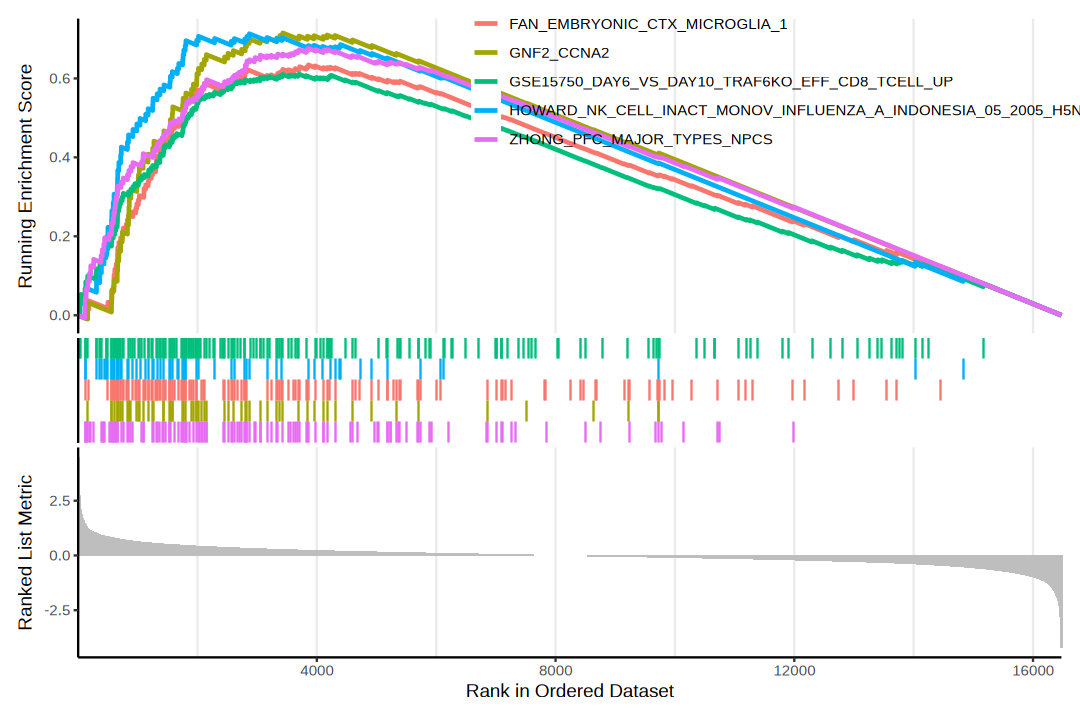

In [60]:
gseaplot2(gseaRes, geneSetID = 1:5)

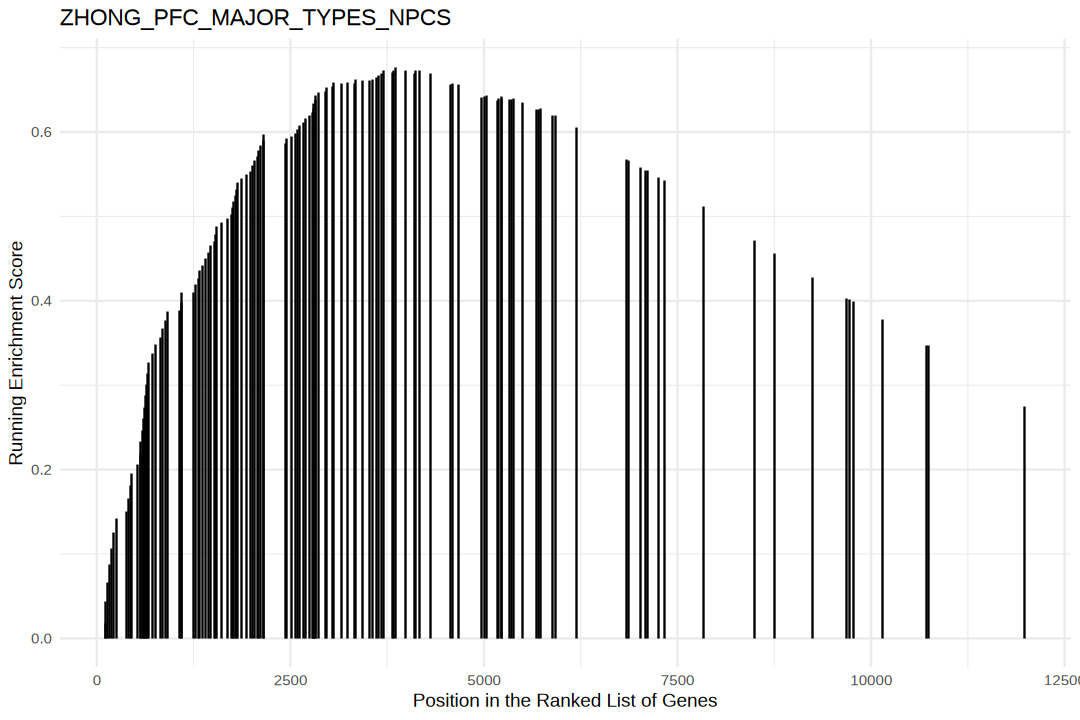

In [61]:
gsearank(gseaRes, 1, title = gseaRes[1, "Description"])

Picking joint bandwidth of 0.152



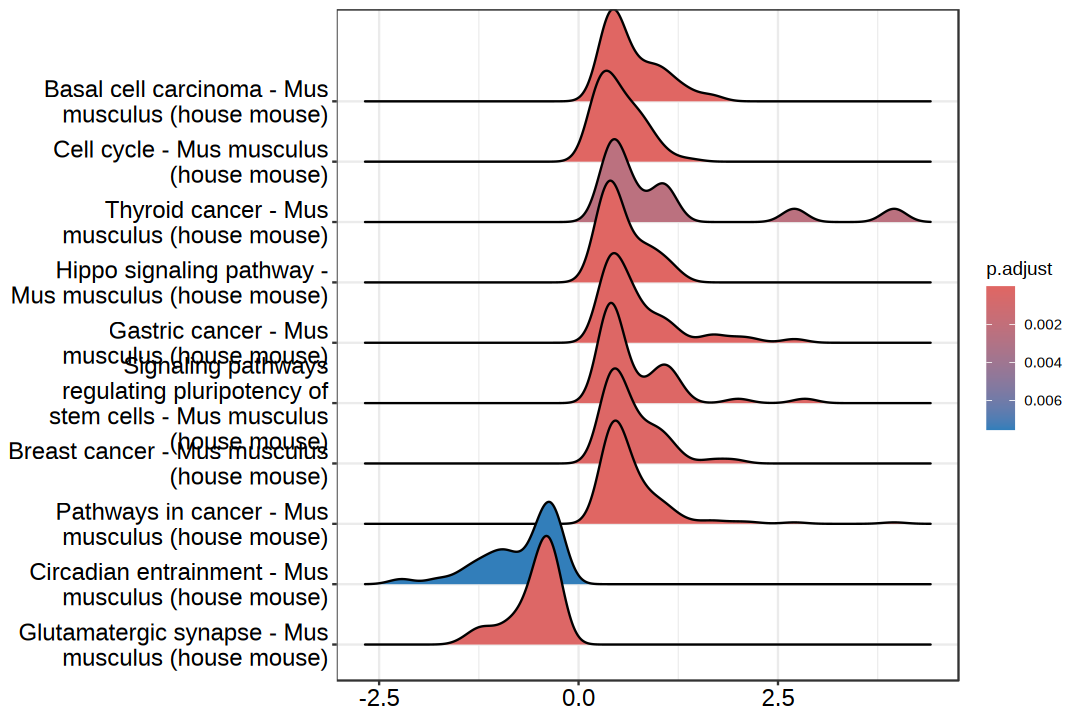

In [62]:
options(repr.plot.width = 9, repr.plot.height = 6)
ridgeplot(gkeggRes, showCategory = 10)

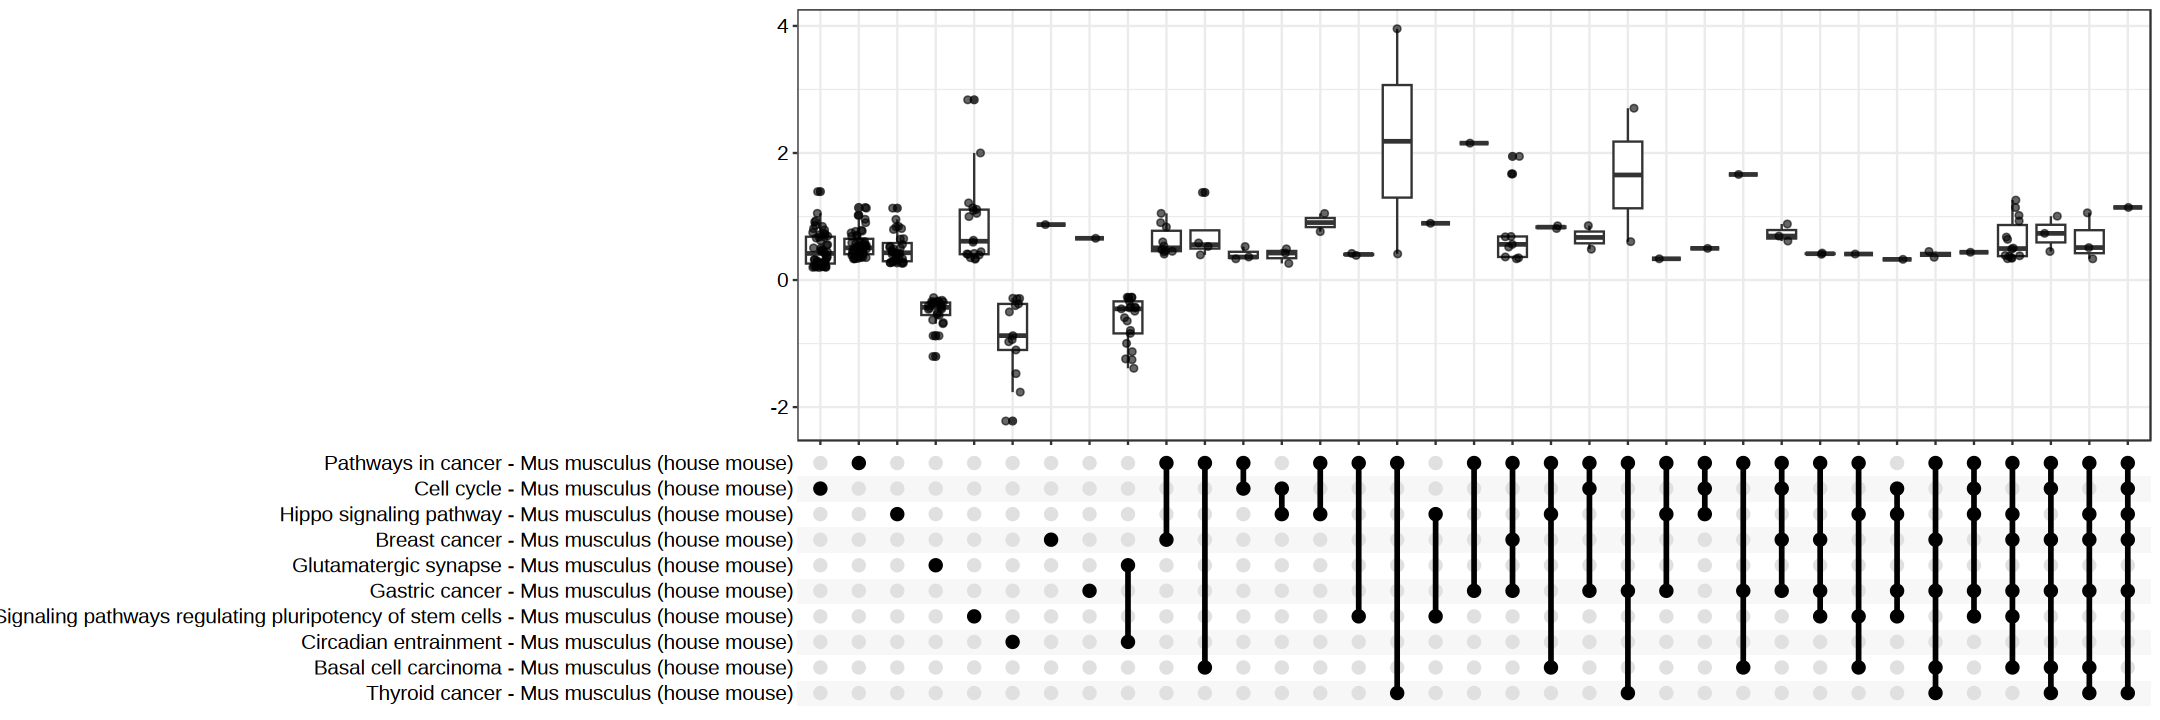

In [63]:
options(repr.plot.width = 18, repr.plot.height = 6)
upsetplot(gkeggRes)

# Term Analysis

In [1]:
suppressPackageStartupMessages(library(GO.db))

In [2]:
select(GO.db, keys = keys(GO.db, keytype = "GOID")[1:2], columns = keytypes(GO.db))

'select()' returned 1:1 mapping between keys and columns



GOID,DEFINITION,ONTOLOGY,TERM
<chr>,<chr>,<chr>,<chr>
GO:0000001,"The distribution of mitochondria, including the mitochondrial genome, into daughter cells after mitosis or meiosis, mediated by interactions between mitochondria and the cytoskeleton.",BP,mitochondrion inheritance
GO:0000002,The maintenance of the structure and integrity of the mitochondrial genome; includes replication and segregation of the mitochondrial chromosome.,BP,mitochondrial genome maintenance


In [3]:
suppressPackageStartupMessages(library(KEGGREST))

In [4]:
pathway_list <- keggList("pathway", "mmu")
head(pathway_list)

mmu01100 
             "Metabolic pathways - Mus musculus (house mouse)" 
                                                      mmu01200 
              "Carbon metabolism - Mus musculus (house mouse)" 
                                                      mmu01210 
"2-Oxocarboxylic acid metabolism - Mus musculus (house mouse)" 
                                                      mmu01212 
          "Fatty acid metabolism - Mus musculus (house mouse)" 
                                                      mmu01230 
    "Biosynthesis of amino acids - Mus musculus (house mouse)" 
                                                      mmu01232 
          "Nucleotide metabolism - Mus musculus (house mouse)"

In [5]:
library(msigdbr)

In [6]:
msigdbrGenes <- msigdbr(species = "Mus musculus")
head(msigdbrGenes, n = 1)

gs_cat,gs_subcat,gs_name,gene_symbol,entrez_gene,ensembl_gene,human_gene_symbol,human_entrez_gene,human_ensembl_gene,gs_id,gs_pmid,gs_geoid,gs_exact_source,gs_url,gs_description,taxon_id,ortholog_sources,num_ortholog_sources
<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<dbl>
C3,MIR:MIR_Legacy,AAACCAC_MIR140,Abcc4,239273,ENSMUSG00000032849,ABCC4,10257,ENSG00000125257,M12609,,,,,"Genes having at least one occurence of the motif AAACCAC in their 3' untranslated region. The motif represents putative target (that is, seed match) of human mature miRNA hsa-miR-140 (v7.1 miRBase).",10090,Ensembl|HGNC|HomoloGene|Inparanoid|NCBI|OMA|OrthoDB|OrthoMCL|Panther,9


In [ ]:
# suppressPackageStartupMessages(library(pathview))
# genes_logfc <- deseq2_result |> 
#     select(ENTREZID, logFC) |> 
#     filter(!is.na(ENTREZID) & ENTREZID != "")
# pathview(
#     gene.data = genes_logfc[, "logFC"], 
#     pathway.id = "04060", species = "mmu", 
#     out.suffix = "")